# Question-Adaptive Visual Token Selection for Vision-Language Models

**Experimental notebook**: CLIP ViT-B/16 (frozen) + question encoder (frozen) + question-conditioned *selector* + projector + Qwen2.5-0.5B-Instruct (frozen + LoRA), evaluated on VQAv2.

| Part | Sections | Content |
|---|---|---|
| I. Framing | 1 – 3 | Motivation, theoretical background, environment |
| II. Data | 4 – 5 | VQAv2, official metric, image preprocessing |
| III. Encoders | 6 – 8 | CLIP vision, question encoder, token analysis |
| IV. Selection | 9 – 13 | Scorers, cross-attention, fixed Top-K, conditioned Top-K, dynamic budget |
| V. VLM | 14 – 16 | Projector, integration into Qwen, full forward pass |
| VI. Training | 17 – 18 | LoRA, phases A → D |
| VII. Experiments | 19 – 21 | Baselines, benchmark, visualizations and ablations |
| VIII. Conclusion | 22 – 23 | Results, limitations, future work |

**Notebook rules**

1. Always run **section 3** first: it defines `cfg`, `DEVICE`, `DTYPE` and the utilities.
2. `DEBUG = True` (section 3.6) runs the whole pipeline on ~200 examples in a few minutes. Validate each section in DEBUG before switching to full mode.
3. Each section writes files to persistent storage; after a disconnection, we **reload** instead of recomputing (`load_or_compute`, section 3.7).
4. No number is written by hand in this notebook: all results are measured.

---
# Part I: framing

## Section 1. Introduction and motivation

### 1.1 The problem

A LLaVA-style VLM turns the image into a sequence of visual tokens, then feeds it to the LLM together with the question. With CLIP ViT-B/16 at 224×224, that is **196 visual tokens for every image**, whether the question is about the whole scene ("How many people are there?") or about a single object ("What color is the car?").

Yet the cost of the LLM grows with the sequence length $T$: linearly for the projections and the MLP, quadratically for attention. In our setup, visual tokens make up about **three quarters** of the sequence. Most of them are useless for answering a localized question.

### 1.2 The hypothesis

> A **question-conditioned** selection of visual tokens can sharply reduce the number of tokens sent to the LLM without degrading accuracy much. It does better than a selection that ignores the question, for the same number of tokens.

### 1.3 Research questions

| | Question | How we answer it |
|---|---|---|
| **RQ1** | At equal K, does a question-conditioned selection beat one that ignores the question? | Compare Question-Conditioned Top-K and Fixed Top-K (4 variants) for each K (sections 19 and 20) |
| **RQ2** | How low can K go before a significant degradation? | Accuracy = f(K) curve, gap to Full Tokens with confidence intervals |
| **RQ3** | Does the dynamic budget dominate the fixed budget on the accuracy / tokens curve? | Position of the "dynamic budget" point relative to the Pareto front of fixed Top-K |
| **RQ4** | Do FLOP savings translate into real latency savings? | Benchmark measured from pixels: ViT + selector + prefill + decoding |

### 1.4 Architecture

🔒 = frozen, 🔥 = trained

```
                     ┌──────────────────────────┐
  Image 3×224×224 ──►│ 🔒 CLIP ViT-B/16          │── V : 196×768 (penultimate layer, without CLS) ───┐
                     └──────────────────────────┘                                                   │
                                                                                                     ▼
                     ┌──────────────────────────┐                                  ┌──────────────────────────┐
  Question ─────────►│ 🔒 Question encoder       │── Q : M×512,  q̄ : 512 ─────────►│ 🔥 Selector               │── s : 196
                     │   (CLIP text)             │                                  │   (cross-attention, MLP…) │     │
                     └──────────────────────────┘                                  └──────────────────────────┘     │
                                                                                                                     ▼
                                                                                    ┌──────────────────────────┐
                                                                                    │ 🔥 Budget (fixed K or     │── K ∈ {24,49,98,147,196}
                                                                                    │    budget head)           │
                                                                                    └──────────────────────────┘
                                                                                                     │
                     Top-K(s, K) → sort indices (spatial order) → gather(V)  ◄──────────────────────┘
                                         │
                                         ▼  V_K : K×768
                     ┌──────────────────────────┐
                     │ 🔥 Projector (MLP)        │── K×896
                     └──────────────────────────┘
                                         │
                                         ▼
     [prompt] <|vision_start|> K visual tokens <|vision_end|> [question]   (T ≈ K + 40 tokens)
                                         │
                                         ▼
                     ┌──────────────────────────┐
                     │ 🔒 Qwen2.5-0.5B + 🔥 LoRA │──►  "red"
                     └──────────────────────────┘
```

### 1.5 The running example

We follow a single example throughout the notebook: a COCO image with a red car, a house and some people, and the question **"What color is the car?"**. In each section, we will print the actual shapes for this example.

| Step | What the example becomes | Shape | Section |
|---|---|---|---|
| Raw image | COCO photo | H×W×3 | 4 |
| Preprocessing | Resized and normalized image | 3×224×224 | 5 |
| CLIP ViT | 1 CLS + 196 patches (14×14 grid) | 197×768 | 6 |
| CLS removal | Visual tokens | V : 196×768 | 6 |
| Question | "What color is the car?" tokenized | Q : M×512, q̄ : 512 | 7 |
| Selector | One score per patch: those of the car are high | s : 196 | 9 – 12 |
| Budget | Simple question, localized object → K = 24 | K | 13 |
| Top-K | The 24 patches of the car, in spatial order | 24×768 | 11 – 12 |
| Projector | Translation into Qwen's space | 24×896 | 14 |
| LLM sequence | Prompt + 24 visual tokens + question | T ≈ 64 × 896 | 15 |
| Qwen + LoRA | Generation | "red" | 16 – 18 |
| Evaluation | Comparison with the 10 human answers | acc ∈ [0, 1] | 4, 20 |

## Section 2. Theoretical background

The bare minimum to get started. The rest (cross-attention in detail, STE, Gumbel, LoRA, RoPE, causal attention) is introduced in the section where we need it.

### 2.1 Attention

We start from three matrices obtained by linear projection of the input: the queries $Q \in \mathbb{R}^{n \times d_k}$, the keys $K \in \mathbb{R}^{m \times d_k}$ and the values $V \in \mathbb{R}^{m \times d_v}$.

$$
\mathrm{Attention}(Q, K, V) = \mathrm{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}}\right) V
$$

* $QK^\top \in \mathbb{R}^{n \times m}$ measures how well each query "matches" each key.
* The **softmax** is applied row by row: each query distributes a mass of 1 over the $m$ keys.
* The output of each query is a **weighted average of the values**.

**Why divide by $\sqrt{d_k}$?** If the components of $q$ and $k$ are independent, with mean 0 and variance 1, then $q \cdot k = \sum_{i=1}^{d_k} q_i k_i$ has variance $d_k$. Without normalization, the logits become very large as $d_k$ grows, the softmax saturates (almost one-hot) and its gradients vanish. Dividing by $\sqrt{d_k}$ brings the variance back to 1.

**Multi-head.** We split $d_{model}$ into $h$ heads of dimension $d_k = d_{model}/h$. Each head computes its own attention, then we concatenate and project:

$$
\mathrm{MHA}(X) = \mathrm{Concat}(\mathrm{head}_1, \dots, \mathrm{head}_h)\, W^O,
\qquad \mathrm{head}_i = \mathrm{Attention}(X W_i^Q, X W_i^K, X W_i^V)
$$

* **Self-attention**: $Q$, $K$ and $V$ come from the same sequence (the ViT, the LLM).
* **Cross-attention**: $Q$ comes from one sequence, $K$ and $V$ from another. This is what our *selector* will use (section 10): the words of the question "look at" the patches.

### 2.2 The Vision Transformer (ViT-B/16)

1. **Patch splitting.** The $224 \times 224 \times 3$ image is split into a $14 \times 14$ grid of $16 \times 16$-pixel patches, i.e. $N = 196$ patches. Each patch contains $16 \cdot 16 \cdot 3 = 768$ values.
2. **Patch embedding.** Each flattened patch is linearly projected: $x_p E$, with $E \in \mathbb{R}^{768 \times D}$ and $D = 768$. In practice, this is a convolution with kernel 16 and stride 16.
3. **CLS token.** A learned vector $x_{cls}$ is prepended; it serves as a global summary of the image.
4. **Positional embedding.** Attention is permutation-invariant: without position information, the model would not know where each patch is. We add a learned position vector $E_{pos} \in \mathbb{R}^{197 \times D}$.

$$
z_0 = [\,x_{cls};\ x_1 E;\ x_2 E;\ \dots;\ x_{196} E\,] + E_{pos} \in \mathbb{R}^{197 \times 768}
$$

5. **12 Transformer blocks** (pre-LayerNorm): $z'_\ell = z_{\ell-1} + \mathrm{MHA}(\mathrm{LN}(z_{\ell-1}))$, then $z_\ell = z'_\ell + \mathrm{MLP}(\mathrm{LN}(z'_\ell))$.

For us, each patch yields a **visual token**. We will take the outputs of the **penultimate layer**, without the CLS: $V \in \mathbb{R}^{196 \times 768}$. The justification is given in section 6.

### 2.3 The LLaVA-style VLM architecture

$$
\underbrace{\text{image}}_{3\times224\times224}
\xrightarrow{\ \text{ViT}\ } Z_v \in \mathbb{R}^{196 \times 768}
\xrightarrow{\ \text{projector}\ } H_v \in \mathbb{R}^{196 \times 896}
\xrightarrow{\ \text{concat with the text}\ } [\,H_{prompt};\ H_v;\ H_{question}\,]
\xrightarrow{\ \text{LLM}\ } \text{answer}
$$

* The **projector** translates the ViT space into the LLM embedding space. The two spaces were learned separately, and nothing aligns them at the start.
* The visual tokens are given to the LLM through `inputs_embeds`, **in place of** word embeddings.
* The loss is the cross-entropy **only on the answer tokens**: $\mathcal{L} = -\sum_{t \in \text{answer}} \log p_\theta(y_t \mid y_{<t}, H_v, \text{question})$.

### 2.4 Visual token pruning

**The cost.** For one LLM block, the prefill of a sequence of length $T$ costs roughly

$$
\mathrm{FLOPs}_{\text{block}} \approx \underbrace{2\,T\,(2d^2 + 2 d\, d_{kv})}_{\text{projections } Q,K,V,O} \;+\; \underbrace{4\,T^2 d}_{\text{scores and aggregation}} \;+\; \underbrace{6\,T\, d\, d_{ff}}_{\text{SwiGLU MLP}}
$$

For Qwen2.5-0.5B ($d = 896$, $d_{ff} = 4864$), the term linear in $T$ dominates at the lengths considered. Going from $T \approx 236$ (196 visual tokens) to $T \approx 64$ ($K = 24$) therefore divides the prefill cost by about $3.7$. This theoretical calculation will be **verified by a measurement** in section 20 (RQ4).

**The principle.** We compute a score $s_i$ for each visual token, then keep the $K$ best:

$$
\mathcal{S} = \mathrm{TopK}(s, K), \qquad V_K = \{\, v_i : i \in \mathcal{S} \,\} \in \mathbb{R}^{K \times 768}
$$

Two choices structure the whole project:

| | **Question-independent** | **Question-conditioned** |
|---|---|---|
| **Fixed K** | Random, grid, CLS attention, learned scorer without the question (section 11) | Selector A / B / C + Top-K (section 12) |
| **Dynamic K** | (out of scope) | Mass threshold, entropy, budget head (section 13) |

Pruning can also be done **inside the LLM** (FastV drops tokens after the first layers based on the LLM's attention). We prune **before** the LLM, so that the savings apply to all of its layers. FastV remains an optional comparison (section 19).

## Section 3. Environment and configuration

**Goal**: a reproducible notebook that can restart after a disconnection without recomputing everything.

| Subsection | Role |
|---|---|
| 3.1 | Detect the environment (Colab, Kaggle, local) and choose persistent storage |
| 3.2 | Install the libraries and **pin their versions** in a lock file |
| 3.3 | Import and print the versions |
| 3.4 | Check the GPU and choose **fp16 or bf16** |
| 3.5 | Fix all the seeds |
| 3.6 | Central configuration + `DEBUG` flag |
| 3.7 | Resume (`load_or_compute`) and shape-printing utilities |
| 3.8 | Section checks |

### 3.1 Runtime environment and persistent storage

Two kinds of storage, with two different roles:

* **Persistent storage** (`PROJECT_DIR`): Google Drive on Colab. This is where we put whatever is expensive to recompute: split ID lists, feature cache, checkpoints, results.
* **Fast local disk** (`FAST_DIR`): this is where we put the **raw COCO images**. Reading thousands of small files from Drive is very slow; we would rather re-download them at each session.

Determinism-related environment variables must be set **before the first torch import**: that is why they are in the very first code cell.

In [1]:
# 3.1 — Runtime environment and storage
import os
import sys
import platform
from pathlib import Path

# Must be set BEFORE the first `import torch` (cuBLAS determinism, see 3.5)
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")

PROJECT_NAME = "Question_Adaptive_VLM"


def detect_env() -> str:
    """Returns 'colab', 'kaggle' or 'local'."""
    try:
        import google.colab  # noqa: F401
        return "colab"
    except ImportError:
        pass
    if "KAGGLE_KERNEL_RUN_TYPE" in os.environ:
        return "kaggle"
    return "local"


ENV = detect_env()

if os.environ.get("VLM_PROJECT_DIR"):            # manual override possible
    PROJECT_DIR = Path(os.environ["VLM_PROJECT_DIR"])
    FAST_DIR = PROJECT_DIR / "fast"
elif ENV == "colab":
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        PROJECT_DIR = Path("/content/drive/MyDrive") / PROJECT_NAME
    except Exception as e:                          # e.g. Colab kernel driven from VS Code
        print(f"⚠️ Drive not mounted ({type(e).__name__}: {e})")
        print("   → local storage: it will be LOST at the end of the session.")
        PROJECT_DIR = Path("/content") / PROJECT_NAME
    FAST_DIR = Path("/content/fast")
elif ENV == "kaggle":
    PROJECT_DIR = Path("/kaggle/working") / PROJECT_NAME   # kept only via "Save Version"
    FAST_DIR = Path("/tmp/fast")
else:
    PROJECT_DIR = Path.cwd() / "work"
    FAST_DIR = PROJECT_DIR / "fast"

PROJECT_DIR.mkdir(parents=True, exist_ok=True)
FAST_DIR.mkdir(parents=True, exist_ok=True)

print(f"Environment     : {ENV}")
print(f"Python          : {platform.python_version()}  ({platform.system()})")
print(f"Persistent storage (PROJECT_DIR) : {PROJECT_DIR}")
print(f"Fast disk          (FAST_DIR)    : {FAST_DIR}")

Environment     : local
Python          : 3.13.2  (Windows)
Persistent storage (PROJECT_DIR) : c:\Users\riahi\Desktop\Question-Adaptive Visual Token Selection for Efficient VLM\work
Fast disk          (FAST_DIR)    : c:\Users\riahi\Desktop\Question-Adaptive Visual Token Selection for Efficient VLM\work\fast


### 3.2 Installation and version pinning

* **First run**: we install the missing libraries, then write their exact versions to `requirements.lock.txt` (on persistent storage).
* **Subsequent runs**: we reinstall **exactly** those versions. The notebook therefore does not change behavior if Colab updates its packages.

⚠️ We **never** reinstall `torch`: on Colab and Kaggle, it is built for the machine's CUDA version. Its version is only recorded in the lock. Locally, install it yourself from [pytorch.org](https://pytorch.org) with the right CUDA version.

If this cell **modified** an already-installed library, restart the kernel and run again from 3.1.

In [2]:
# 3.2 — Installation and version pinning
import subprocess
import importlib.util
from importlib.metadata import version, PackageNotFoundError

LOCK_FILE = PROJECT_DIR / "requirements.lock.txt"

# pip name → import name
LIBS = {
    "transformers": "transformers",
    "peft": "peft",
    "accelerate": "accelerate",
    "datasets": "datasets",
    "numpy": "numpy",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
    "pillow": "PIL",
    "tqdm": "tqdm",
    "scikit-learn": "sklearn",
}


def pip_install(*args: str) -> None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "--root-user-action=ignore", *args])


if importlib.util.find_spec("torch") is None:
    raise RuntimeError("PyTorch is missing: install the appropriate CUDA build (https://pytorch.org), then rerun.")

if LOCK_FILE.exists():
    print(f"📌 Pinned versions found → installing from {LOCK_FILE.name}")
    pip_install("-r", str(LOCK_FILE))
else:
    missing = [pkg for pkg, mod in LIBS.items() if importlib.util.find_spec(mod) is None]
    if missing:
        print("Installing:", ", ".join(missing))
        pip_install(*missing)
    lines = [f"# torch=={version('torch')}  (not reinstalled, depends on CUDA)"]
    lines += [f"{pkg}=={version(pkg)}" for pkg in LIBS]
    LOCK_FILE.write_text("\n".join(lines) + "\n")
    print(f"📌 Versions pinned in {LOCK_FILE}")

print(LOCK_FILE.read_text())

📌 Pinned versions found → installing from requirements.lock.txt
# torch==2.10.0  (not reinstalled, depends on CUDA)
transformers==5.0.0
peft==0.21.3
accelerate==1.15.0
datasets==4.5.0
numpy==2.2.2
pandas==2.2.3
matplotlib==3.10.0
pillow==11.1.0
tqdm==4.67.1
scikit-learn==1.8.0



### 3.3 Imports and versions

All the "heavy" imports of the notebook are centralized here. The following sections will only import what is specific to them.

In [3]:
# 3.3 — Imports and versions
import json
import math
import time
import random
import hashlib
from dataclasses import dataclass, asdict, fields

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F

import transformers
import peft
import accelerate
import datasets

transformers.logging.set_verbosity_error()   # hides verbose loading warnings

for lib in (torch, transformers, peft, accelerate, datasets, np, pd):
    print(f"{lib.__name__:<13}{lib.__version__}")
print(f"{'CUDA (torch)':<13}{torch.version.cuda}")

torch        2.10.0+cpu
transformers 5.0.0
peft         0.21.3
accelerate   1.15.0
datasets     4.5.0
numpy        2.2.2
pandas       2.2.3
CUDA (torch) None


### 3.4 GPU and compute precision

| Format | Exponent bits | Mantissa bits | Range | Note |
|---|---|---|---|---|
| fp32 | 8 | 23 | ±3.4·10³⁸ | Reference, slow and memory-hungry |
| **fp16** | 5 | 10 | ±65,504 | Overflow risk: a `GradScaler` is needed for training |
| **bf16** | 8 | 7 | ±3.4·10³⁸ | Same range as fp32, less precise, no `GradScaler` needed |

bf16 is only **hardware-accelerated** from the Ampere architecture onward (compute capability ≥ 8.0: A100, L4, RTX 30xx/40xx). On a **T4** (capability 7.5), we use fp16.

⚠️ Pitfall: in recent PyTorch versions, `torch.cuda.is_bf16_supported()` may return `True` on a T4, because bf16 is **emulated** there (hence slow). We test the compute capability directly instead.

In [4]:
# 3.4 — GPU and precision choice
def setup_device():
    if not torch.cuda.is_available():
        print("⚠️ No GPU detected: only DEBUG mode is realistic on CPU.")
        return torch.device("cpu"), torch.float32, {}

    idx = torch.cuda.current_device()
    props = torch.cuda.get_device_properties(idx)
    major, minor = torch.cuda.get_device_capability(idx)
    free_b, total_b = torch.cuda.mem_get_info(idx)

    native_bf16 = major >= 8
    dtype = torch.bfloat16 if native_bf16 else torch.float16
    if native_bf16:
        torch.backends.cuda.matmul.allow_tf32 = True   # accelerated fp32 matmuls (Ampere+)
        torch.backends.cudnn.allow_tf32 = True

    info = {
        "name": props.name,
        "capability": f"{major}.{minor}",
        "total_gb": round(total_b / 1024**3, 1),
        "free_gb": round(free_b / 1024**3, 1),
        "n_sm": props.multi_processor_count,
        "native_bf16": native_bf16,
    }
    return torch.device("cuda", idx), dtype, info


DEVICE, DTYPE, GPU_INFO = setup_device()
USE_GRAD_SCALER = DTYPE == torch.float16    # essential in fp16, useless in bf16

for k, v in GPU_INFO.items():
    print(f"{k:<12}{v}")
print(f"{'device':<12}{DEVICE}")
print(f"{'dtype':<12}{DTYPE}")
print(f"{'GradScaler':<12}{USE_GRAD_SCALER}")

⚠️ No GPU detected: only DEBUG mode is realistic on CPU.
device      cpu
dtype       torch.float32
GradScaler  False


### 3.5 Seeds and determinism

There are **four independent generators** to seed: `random` (Python), NumPy, torch CPU and torch CUDA. On top of that come two less visible sources of non-determinism:

* **non-deterministic CUDA algorithms** (some cuDNN/cuBLAS convolutions and reductions). We disable them with `cudnn.deterministic` and `torch.use_deterministic_algorithms`. `warn_only=True` reports operations that have no deterministic version instead of crashing;
* **DataLoader workers**, each of which has its own seed. We control them with `worker_init_fn=seed_worker` and `generator=make_generator(seed)`.

Deterministic mode slightly slows down some operations. We will **disable** it for the latency benchmark (section 20).

In [5]:
# 3.5 — Seeds
def set_seed(seed: int, deterministic: bool = True) -> None:
    """Seeds every source of randomness: Python, NumPy, torch (CPU and CUDA)."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)              # CPU
    torch.cuda.manual_seed_all(seed)     # all GPUs (no effect without a GPU)
    torch.backends.cudnn.deterministic = deterministic
    torch.backends.cudnn.benchmark = not deterministic
    torch.use_deterministic_algorithms(deterministic, warn_only=True)


def seed_worker(worker_id: int) -> None:
    """Pass as `worker_init_fn` to the DataLoader: each worker derives its seed from torch's."""
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)


def make_generator(seed: int) -> torch.Generator:
    """Pass as `generator=` to the DataLoader: makes the shuffle order reproducible."""
    g = torch.Generator()
    g.manual_seed(seed)
    return g


SEED = 42
set_seed(SEED)
print(f"Global seed set: {SEED}")

Global seed set: 42


### 3.6 Central configuration

All the project's hyperparameters live in **a single object** `cfg`. No section should hard-code a number: it reads `cfg`.

A few choices worth understanding:

* **The K buckets**: $\{24, 49, 98, 147, 196\} \approx 196 \times \{\tfrac18, \tfrac14, \tfrac12, \tfrac34, 1\}$. They cover the range from 12.5% to 100% of the tokens.
* **`vision_feature_layer = -2`**: the penultimate layer of the ViT (justification in section 6).
* **LoRA r = 16 on the 7 projections** of each Qwen block: this gives about 8.8M trainable parameters (we will check this in section 17).
* **Subset sizes** are expressed in **number of images**, because the train / dev / test split is done by `image_id` (an image has ~5 questions on average in VQAv2).
* **`run_name`**: DEBUG artifacts and full-mode artifacts go into **separate folders**. Otherwise, `load_or_compute` would reload, in full mode, a cache computed on 40 images.

The learning rates and loss weights are **starting values**; they will be tuned on the dev set in section 18.

In [6]:
# 3.6 — Central configuration
DEBUG = True    # ← True: ~200 examples, a few minutes. False: full run.


@dataclass
class Config:
    # ---------------- General
    debug: bool = DEBUG
    seed: int = SEED
    eval_seeds: tuple = (0, 1, 2)            # 3 seeds for the key comparisons
    env: str = ENV
    device: str = str(DEVICE)
    dtype: str = str(DTYPE).replace("torch.", "")

    # ---------------- Paths (filled in __post_init__)
    project_dir: str = str(PROJECT_DIR)
    fast_dir: str = str(FAST_DIR)
    run_name: str = ""
    data_dir: str = ""          # VQAv2 JSON, splits, DataFrame (shared between DEBUG and full)
    image_dir: str = ""         # raw COCO images (fast disk)
    run_dir: str = ""           # everything that depends on the run
    cache_dir: str = ""         # CLIP features, CLS attention, teacher attention
    ckpt_dir: str = ""          # projector, LoRA, selector, budget head
    results_dir: str = ""       # raw result CSVs
    fig_dir: str = ""           # figures

    # ---------------- Models (Hugging Face)
    clip_name: str = "openai/clip-vit-base-patch16"
    distilbert_name: str = "distilbert-base-uncased"
    llm_name: str = "Qwen/Qwen2.5-0.5B-Instruct"

    # ---------------- Dimensions
    image_size: int = 224
    patch_size: int = 16
    grid_size: int = 14
    n_patches: int = 196
    d_vision: int = 768
    d_text: int = 512               # CLIP text
    d_distilbert: int = 768
    d_llm: int = 896                # Qwen2.5-0.5B
    vision_feature_layer: int = -2  # penultimate layer of the ViT
    max_question_len: int = 32      # in CLIP tokens (max context: 77)
    max_answer_len: int = 8         # in Qwen tokens

    # ---------------- Token budgets
    k_buckets: tuple = (24, 49, 98, 147, 196)
    k_fixed: tuple = (24, 49, 98, 147)
    k_blind: int = 0                # blind baseline: no visual token

    # ---------------- Selector and budget (starting values)
    selector_dim: int = 256
    selector_heads: int = 8
    gumbel_scale_start: float = 1.0
    gumbel_scale_end: float = 0.0
    lambda_distill: float = 0.5
    budget_rho: float = 0.9         # cumulative mass threshold (training-free budget)

    # ---------------- Projector
    projector_type: str = "mlp"     # "linear" or "mlp"
    projector_hidden: int = 896

    # ---------------- LoRA
    lora_r: int = 16
    lora_alpha: int = 32
    lora_dropout: float = 0.05
    lora_targets: tuple = ("q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj")

    # ---------------- Training
    lr_projector: float = 1e-3
    lr_lora: float = 2e-4
    lr_selector: float = 3e-4
    lr_budget: float = 1e-3
    batch_size: int = 16
    grad_accum: int = 4
    weight_decay: float = 0.0
    warmup_ratio: float = 0.03
    max_grad_norm: float = 1.0
    epochs_a: int = 1               # phase A: projector only
    epochs_b: int = 1               # phase B: LoRA
    epochs_c: int = 1               # phase C: selector
    epochs_d: int = 3               # phase D: budget head
    eval_every: int = 500           # in optimization steps
    num_workers: int = 2

    # ---------------- Data (in number of images)
    n_train_images: int = 10_000    # ≈ 54k questions
    n_dev_images: int = 1_000
    n_test_images: int = 2_000      # drawn from val2014 (official test set is unannotated)

    # ---------------- Evaluation and benchmark
    n_bootstrap: int = 1_000
    bench_warmup: int = 10
    bench_reps: int = 50
    bench_batch_sizes: tuple = (1, 8, 32)

    def __post_init__(self):
        if self.debug:
            self.n_train_images, self.n_dev_images, self.n_test_images = 40, 10, 10   # ≈ 200 + 50 + 50 questions
            self.batch_size, self.grad_accum = 4, 1
            self.epochs_a = self.epochs_b = self.epochs_c = self.epochs_d = 1
            self.eval_every = 20
            self.eval_seeds = (0,)
            self.n_bootstrap = 100
            self.bench_warmup, self.bench_reps = 2, 5
            self.num_workers = 0
        self.run_name = "debug" if self.debug else "full"
        root = Path(self.project_dir)
        self.data_dir = str(root / "data")
        self.image_dir = str(Path(self.fast_dir) / "coco")
        self.run_dir = str(root / "runs" / self.run_name)
        for name in ("cache", "ckpt", "results", "fig"):
            setattr(self, f"{name}_dir", str(Path(self.run_dir) / name))

    # --- utilities
    def path(self, kind: str, *parts: str) -> Path:
        """cfg.path('cache', 'clip_train.pt') → Path to the file."""
        return Path(getattr(self, f"{kind}_dir")).joinpath(*parts)

    def make_dirs(self) -> None:
        for f in fields(self):
            if f.name.endswith("_dir"):
                Path(getattr(self, f.name)).mkdir(parents=True, exist_ok=True)

    def validate(self) -> None:
        assert self.image_size // self.patch_size == self.grid_size, "image_size / patch_size ≠ grid_size"
        assert self.grid_size ** 2 == self.n_patches, "grid_size² ≠ n_patches"
        assert list(self.k_buckets) == sorted(set(self.k_buckets)), "k_buckets must be sorted, without duplicates"
        assert all(1 <= k <= self.n_patches for k in self.k_buckets), "K outside [1, n_patches]"
        assert self.k_buckets[-1] == self.n_patches, "the last bucket must be Full Tokens"
        assert set(self.k_fixed) <= set(self.k_buckets), "k_fixed must be included in k_buckets"
        assert self.d_llm % 64 == 0 and self.selector_dim % self.selector_heads == 0
        assert 0 < self.budget_rho < 1 and 0 <= self.lambda_distill

    def to_dict(self) -> dict:
        return {k: (list(v) if isinstance(v, tuple) else v) for k, v in asdict(self).items()}


cfg = Config()
cfg.validate()
cfg.make_dirs()

# Save the run config, with a warning if it changed since the last execution
cfg_file = cfg.path("run", "config.json")
if cfg_file.exists():
    old = json.loads(cfg_file.read_text())
    changed = {k: (old.get(k), v) for k, v in cfg.to_dict().items() if old.get(k) != v}
    if changed:
        print("⚠️ Config changed since the last execution of this run:")
        for k, (a, b) in changed.items():
            print(f"   {k}: {a} → {b}")
        print("   Already-cached artifacts may have been produced with the old config.")
cfg_file.write_text(json.dumps(cfg.to_dict(), indent=2, ensure_ascii=False))

print(f"Mode: {'DEBUG' if cfg.debug else 'FULL'}   (run_name = '{cfg.run_name}')")
print(f"Train / dev / test images: {cfg.n_train_images} / {cfg.n_dev_images} / {cfg.n_test_images}")
print(f"K buckets: {cfg.k_buckets}   ({[f'{k / cfg.n_patches:.0%}' for k in cfg.k_buckets]})")
print(f"Effective batch: {cfg.batch_size} × {cfg.grad_accum} = {cfg.batch_size * cfg.grad_accum}")
print(f"Run dir: {cfg.run_dir}")

⚠️ Config changed since the last execution of this run:
   project_dir: C:\Users\riahi\Desktop\Question-Adaptive Visual Token Selection for Efficient VLM\work → c:\Users\riahi\Desktop\Question-Adaptive Visual Token Selection for Efficient VLM\work
   fast_dir: C:\Users\riahi\Desktop\Question-Adaptive Visual Token Selection for Efficient VLM\work\fast → c:\Users\riahi\Desktop\Question-Adaptive Visual Token Selection for Efficient VLM\work\fast
   data_dir: C:\Users\riahi\Desktop\Question-Adaptive Visual Token Selection for Efficient VLM\work\data → c:\Users\riahi\Desktop\Question-Adaptive Visual Token Selection for Efficient VLM\work\data
   image_dir: C:\Users\riahi\Desktop\Question-Adaptive Visual Token Selection for Efficient VLM\work\fast\coco → c:\Users\riahi\Desktop\Question-Adaptive Visual Token Selection for Efficient VLM\work\fast\coco
   run_dir: C:\Users\riahi\Desktop\Question-Adaptive Visual Token Selection for Efficient VLM\work\runs\debug → c:\Users\riahi\Desktop\Question-

### 3.7 Resume and display utilities

**`load_or_compute`** is the mechanism that makes the notebook restartable: if the file exists, we reload it; otherwise, we compute it and then save it.

Writing is **atomic**: we first write to `file.tmp`, then rename. If Colab disconnects in the middle of a save, an incomplete `.tmp` is left behind, but never a fake "finished" file that would be wrongly reloaded.

**`show`** prints the shape, dtype and a few statistics of a tensor. We will use it at each step of the running example.

In [7]:
# 3.7 — Resume and display utilities
def load_or_compute(path, compute_fn, save_fn=None, load_fn=None, force: bool = False):
    """Reloads `path` if it exists; otherwise runs `compute_fn()`, saves the result and returns it.

    Default: torch.save / torch.load. Pass save_fn(obj, path) and load_fn(path) for another format.
    """
    path = Path(path)
    save_fn = save_fn or (lambda obj, p: torch.save(obj, p))
    load_fn = load_fn or (lambda p: torch.load(p, map_location="cpu", weights_only=False))

    if path.exists() and not force:
        print(f"↩️  Reloaded: {path.name}")
        return load_fn(path)

    t0 = time.perf_counter()
    obj = compute_fn()
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name + ".tmp")
    save_fn(obj, tmp)
    tmp.replace(path)                       # atomic rename
    size_mb = path.stat().st_size / 1024**2
    print(f"💾 Computed and saved: {path.name}  ({time.perf_counter() - t0:.1f} s, {size_mb:.1f} MB)")
    return obj


def show(name: str, x) -> None:
    """Prints shape, dtype, device and statistics of a tensor (or the length of a sequence)."""
    if isinstance(x, torch.Tensor):
        msg = f"{name:<28} {str(tuple(x.shape)):<18} {str(x.dtype).replace('torch.', ''):<9} {x.device}"
        if x.is_floating_point() and x.numel() > 0:
            xf = x.detach().float()
            msg += f"  min={xf.min():+.3f} max={xf.max():+.3f} mean={xf.mean():+.3f} std={xf.std():.3f}"
        print(msg)
    elif hasattr(x, "__len__"):
        print(f"{name:<28} len={len(x)}  type={type(x).__name__}")
    else:
        print(f"{name:<28} {x!r}")


def count_params(module: nn.Module) -> tuple[int, int]:
    """(total parameters, trainable parameters)."""
    total = sum(p.numel() for p in module.parameters())
    trainable = sum(p.numel() for p in module.parameters() if p.requires_grad)
    return total, trainable


def gpu_mem(tag: str = "") -> None:
    if torch.cuda.is_available():
        alloc = torch.cuda.memory_allocated() / 1024**3
        peak = torch.cuda.max_memory_allocated() / 1024**3
        print(f"[GPU {tag}] allocated = {alloc:.2f} GB | peak = {peak:.2f} GB")


show("example", torch.randn(196, 768))

example                      (196, 768)         float32   cpu  min=-4.590 max=+4.629 mean=+0.000 std=1.005


### 3.8 Section 3 checks

1. The GPU is detected (otherwise, a warning: only DEBUG mode is realistic).
2. **Reproducibility**: two draws with the same seed are identical, and a different seed gives a different draw. We test the 4 generators, plus the order of a shuffled `DataLoader`.
3. The run folders are writable.
4. `load_or_compute` computes the first time and reloads the second time.

In [8]:
# 3.8 — Checks
from torch.utils.data import DataLoader


def draw(seed: int) -> dict:
    set_seed(seed)
    out = {
        "python": random.random(),
        "numpy": np.random.rand(3).round(8).tolist(),
        "torch_cpu": torch.rand(3).tolist(),
        "randperm": torch.randperm(cfg.n_patches)[:8].tolist(),
        "dataloader": [b.tolist() for b in DataLoader(range(20), batch_size=5, shuffle=True,
                                                     generator=make_generator(seed),
                                                     worker_init_fn=seed_worker)],
    }
    if torch.cuda.is_available():
        out["torch_cuda"] = torch.rand(3, device="cuda").tolist()
    return out


checks = {}

# 1. GPU
checks["GPU detected"] = torch.cuda.is_available()

# 2. Reproducibility
a, b, c = draw(cfg.seed), draw(cfg.seed), draw(cfg.seed + 1)
checks["same seed → same draw"] = a == b
checks["different seed → different draw"] = all(a[k] != c[k] for k in a)
print("Draw (seed 42):", {k: a[k] for k in ("python", "randperm")})

# 3. Writing
probe = cfg.path("run", ".write_test")
probe.write_text("ok")
checks["run_dir is writable"] = probe.read_text() == "ok"
probe.unlink()

# 4. load_or_compute
test_file = cfg.path("cache", "_test_load_or_compute.pt")
test_file.unlink(missing_ok=True)
x1 = load_or_compute(test_file, lambda: torch.arange(10))
x2 = load_or_compute(test_file, lambda: torch.zeros(10))       # must NOT be executed
checks["load_or_compute reloads the cache"] = torch.equal(x1, x2)
test_file.unlink()

set_seed(cfg.seed)   # start again from a clean state

print()
for name, ok in checks.items():
    print(f"{'✅' if ok else '❌'} {name}")

critical = {k: v for k, v in checks.items() if k != "GPU detected"}
assert all(critical.values()), "A critical check failed: do not move on to section 4."
if not checks["GPU detected"]:
    print("\n⚠️ No GPU: OK for DEBUG, but sections 6 onward will be very slow.")
print("\nSection 3 validated → we can move on to section 4.")

Draw (seed 42): {'python': 0.6394267984578837, 'randperm': [110, 187, 41, 55, 24, 105, 19, 182]}
💾 Computed and saved: _test_load_or_compute.pt  (0.1 s, 0.0 MB)
↩️  Reloaded: _test_load_or_compute.pt

❌ GPU detected
✅ same seed → same draw
✅ different seed → different draw
✅ run_dir is writable
✅ load_or_compute reloads the cache

⚠️ No GPU: OK for DEBUG, but sections 6 onward will be very slow.

Section 3 validated → we can move on to section 4.


---
# Part II: the data

## Section 4. Preparing the VQAv2 dataset

**Goal**: a clean table of (image, question, 10 answers) triplets, train / dev / test splits that share no image, and a reliable implementation of the official metric.

| Subsection | Role |
|---|---|
| 4.1 | Download the VQAv2 question and annotation JSON files (train2014 and val2014) |
| 4.2 | Join questions and annotations on `question_id` → one DataFrame |
| 4.3 | Explore: answer types, frequent question types, question length, answer long tail |
| 4.4 | Split train / dev by `image_id` (from train2014), test from val2014; save the ID lists |
| 4.5 | Download only the COCO 2014 images of the subset |
| 4.6 | Official answer normalization (punctuation, numbers, articles, contractions) |
| 4.7 | Official VQA Accuracy (average over the 10 subsets of 9 annotators) |
| 4.8 | Training target `multiple_choice_answer`; save the normalized DataFrame |
| 4.9 | Section checks |

The COCO images are downloaded **after** the split (4.5): we only fetch the images that are actually in our subset, not the whole of COCO 2014.

### 4.1 Downloading the VQAv2 annotations

**Goal**: get the four official VQAv2 JSON files onto persistent storage (`cfg.data_dir`, shared between DEBUG and full mode).

**What is in these files:**

* **questions** file: one entry per question, with `question_id`, `image_id` and `question`;
* **annotations** file, with the same `question_id`: the **10 human answers** (`answers`), the most frequent one (`multiple_choice_answer`), the `answer_type` (yes/no, number, other) and the `question_type` (the first words of the question, e.g. "what color is the").

The images are **not** in these files: they come from COCO 2014, and we download them in 4.5.

**Why val2014 is our test set**: the answers for the official test-dev / test-std splits are hidden behind an evaluation server. val2014 is annotated, so it serves as our test set. Our dev set is carved out of train2014 (4.4).

Same principle as `load_or_compute`: if a JSON is already there, nothing is downloaded. Each file is written to `.tmp` and then renamed, so an interrupted download never leaves behind a file that looks complete. The URL and file names are fixed properties of the dataset, not hyperparameters, so they stay in this cell rather than in `cfg`.

In [9]:
# 4.1 — Download the VQAv2 JSON files
import shutil
import urllib.request
import zipfile

VQA_DIR = Path(cfg.data_dir) / "vqav2"
VQA_DIR.mkdir(parents=True, exist_ok=True)

VQA_BASE_URL = "https://s3.amazonaws.com/cvmlp/vqa/mscoco/vqa"

# key → (official archive, JSON file inside that archive)
VQA_FILES = {
    "train_questions":   ("v2_Questions_Train_mscoco.zip",   "v2_OpenEnded_mscoco_train2014_questions.json"),
    "train_annotations": ("v2_Annotations_Train_mscoco.zip", "v2_mscoco_train2014_annotations.json"),
    "val_questions":     ("v2_Questions_Val_mscoco.zip",     "v2_OpenEnded_mscoco_val2014_questions.json"),
    "val_annotations":   ("v2_Annotations_Val_mscoco.zip",   "v2_mscoco_val2014_annotations.json"),
}


def fetch_vqa_json(archive: str, member: str) -> Path:
    """Downloads `archive`, extracts `member`, then deletes the archive. Does nothing if the JSON is already there."""
    json_path = VQA_DIR / member
    if json_path.exists():
        print(f"↩️  Already there: {member}")
        return json_path

    t0 = time.perf_counter()

    # 1. Download the archive (to .tmp, then rename)
    zip_path = VQA_DIR / archive
    tmp_zip = zip_path.with_name(zip_path.name + ".tmp")
    urllib.request.urlretrieve(f"{VQA_BASE_URL}/{archive}", tmp_zip)
    tmp_zip.replace(zip_path)

    # 2. Extract only the JSON we need (to .tmp, then rename)
    tmp_json = json_path.with_name(json_path.name + ".tmp")
    with zipfile.ZipFile(zip_path) as zf, zf.open(member) as src, open(tmp_json, "wb") as dst:
        shutil.copyfileobj(src, dst)
    tmp_json.replace(json_path)          # the JSON only appears once it is complete

    # 3. The archive is no longer needed
    zip_path.unlink()

    print(f"⬇️  Downloaded and extracted: {member}  ({time.perf_counter() - t0:.1f} s)")
    return json_path


VQA_JSON = {key: fetch_vqa_json(archive, member) for key, (archive, member) in VQA_FILES.items()}

print()
for key, p in VQA_JSON.items():
    print(f"{key:<18} {p.stat().st_size / 1024**2:>7.1f} MB   {p.name}")

↩️  Already there: v2_OpenEnded_mscoco_train2014_questions.json
↩️  Already there: v2_mscoco_train2014_annotations.json
↩️  Already there: v2_OpenEnded_mscoco_val2014_questions.json
↩️  Already there: v2_mscoco_val2014_annotations.json

train_questions       40.0 MB   v2_OpenEnded_mscoco_train2014_questions.json
train_annotations    339.0 MB   v2_mscoco_train2014_annotations.json
val_questions         19.3 MB   v2_OpenEnded_mscoco_val2014_questions.json
val_annotations      163.8 MB   v2_mscoco_val2014_annotations.json


### 4.2 Joining questions and annotations

**Goal**: one row per question, with everything we need later: `coco_split`, `image_id`, `question`, `question_id`, `question_type`, `answer_type`, `multiple_choice_answer` and `answers` (the list of the 10 human answers).

**Concept: the join key.** Questions and annotations live in two separate files, linked by `question_id`. We use `merge(..., validate="one_to_one")`: pandas raises an error if a `question_id` appears twice on either side, which would otherwise **silently duplicate rows**. We also check that both files give the same `image_id` for each question.

**What we drop**: `answer_confidence` ("yes" / "maybe" / "no") and `answer_id`. The official VQA metric does not use them.

**Caching**: parsing the annotations JSON is the slow part. The joined DataFrame is saved with `load_or_compute` in `cfg.data_dir`, not in the run's `cache_dir`, because it does not depend on DEBUG. We save it as a pickle rather than Parquet, because the `answers` column holds lists and `pyarrow` is not in our lock file.

No answer normalization yet: that comes in 4.6. For the running example, we only count the questions that are exactly "What color is the car?". The actual image is chosen once the images are downloaded (4.5).

In [10]:
# 4.2 — Join questions and annotations into one DataFrame
import gc


def load_split(split: str) -> pd.DataFrame:
    """Reads the questions and annotations of one split ('train' or 'val') and joins them on question_id."""
    with open(VQA_JSON[f"{split}_questions"], encoding="utf-8") as f:
        questions = pd.DataFrame(json.load(f)["questions"])        # columns: image_id, question, question_id

    with open(VQA_JSON[f"{split}_annotations"], encoding="utf-8") as f:
        raw = json.load(f)["annotations"]
    annotations = pd.DataFrame({
        "question_id":            [a["question_id"] for a in raw],
        "image_id_ann":           [a["image_id"] for a in raw],     # only used to cross-check, then dropped
        "question_type":          [a["question_type"] for a in raw],
        "answer_type":            [a["answer_type"] for a in raw],
        "multiple_choice_answer": [a["multiple_choice_answer"] for a in raw],
        # Only the answer strings are kept: the official metric ignores `answer_confidence`
        "answers":                [[x["answer"] for x in a["answers"]] for a in raw],
    })
    del raw

    # validate="one_to_one" raises an error if a question_id appears twice on either side
    df = questions.merge(annotations, on="question_id", how="inner", validate="one_to_one")
    assert len(df) == len(questions) == len(annotations), "some questions have no annotation (or the reverse)"
    assert (df["image_id"] == df["image_id_ann"]).all(), "image_id differs between questions and annotations"
    df = df.drop(columns="image_id_ann")
    df.insert(0, "coco_split", f"{split}2014")                     # needed to build the image path (4.5)
    return df


def build_vqa_dataframe() -> pd.DataFrame:
    df = pd.concat([load_split("train"), load_split("val")], ignore_index=True)
    gc.collect()                                                    # free the raw JSON (several GB of Python objects)
    return df


# Independent of DEBUG / full → stored in data_dir, not in the run's cache_dir
vqa_df = load_or_compute(
    cfg.path("data", "vqav2_joined.pkl"),
    build_vqa_dataframe,
    save_fn=lambda obj, p: obj.to_pickle(p),
    load_fn=pd.read_pickle,
)

assert vqa_df["question_id"].is_unique, "question_id is not unique across train2014 and val2014"

print()
show("vqa_df", vqa_df)
print(vqa_df.dtypes.to_string())

print("\nPer COCO split:")
print(vqa_df.groupby("coco_split").agg(questions=("question_id", "size"),
                                       images=("image_id", "nunique")).to_string())
print("\nNumber of human answers per question:", vqa_df["answers"].map(len).value_counts().to_dict())

display(vqa_df.head(3))

# Running example: how many questions are exactly "What color is the car?", and what do people answer?
example_rows = vqa_df[vqa_df["question"].str.lower() == "what color is the car?"]
print(f'Running example: {len(example_rows)} questions are exactly "What color is the car?"')
print("Most frequent multiple_choice_answer:")
print(example_rows["multiple_choice_answer"].value_counts().head(5).to_string())

↩️  Reloaded: vqav2_joined.pkl

vqa_df                       len=658111  type=DataFrame
coco_split                object
image_id                   int64
question                  object
question_id                int64
question_type             object
answer_type               object
multiple_choice_answer    object
answers                   object

Per COCO split:
            questions  images
coco_split                   
train2014      443757   82783
val2014        214354   40504

Number of human answers per question: {10: 658111}


,coco_split,image_id,question,question_id,question_type,answer_type,multiple_choice_answer,answers
0,train2014,458752,What is this photo taken looking through?,458752000,what is this,other,net,"[net, net, net, netting, net, net, mesh, net, ..."
1,train2014,458752,What position is this man playing?,458752001,what,other,pitcher,"[pitcher, catcher, pitcher, pitcher, pitcher, ..."
2,train2014,458752,What color is the players shirt?,458752002,what color is the,other,orange,"[orange, orange, orange, orange, orange, orang..."


Running example: 306 questions are exactly "What color is the car?"
Most frequent multiple_choice_answer:
multiple_choice_answer
white     74
red       52
black     45
blue      43
silver    32


### 4.3 Exploring the data

**Goal**: understand what the model will face before training anything. The exploration runs on the **full** train2014 / val2014 (cheap: it is only a DataFrame), not on the DEBUG subset.

| # | Question | Why it matters for us |
|---|---|---|
| 1 | Share of yes/no, number, other, per split | val2014 is our test set: its distribution should match train2014. Results are reported per answer type in section 20 |
| 2 | Most frequent question types | Section 21 analyses the budgets per question type |
| 3 | Question length (in words) | Compared with `cfg.max_question_len` (in CLIP tokens). Exact count in section 7 |
| 4 | Answer distribution | How concentrated are the answers? We expect a long tail: a few very frequent answers and many rare ones. The cell measures it |
| 5 | Language prior | How well can one answer **without the image**? |

**Concept: the language prior.** Many questions can be partly answered from the text alone: "Is there…?" → "yes", "What color is the car?" → "white" (as seen in 4.2). VQAv2 was built with *complementary pairs* (same question, two similar images, two different answers) to reduce this bias, but some of it remains. We measure it with the simplest image-free predictor: *the most frequent answer of the question type*, **fitted on train2014 and evaluated on val2014**.

This is why section 18 trains a **blind baseline** ($K = 0$): any selection of visual tokens must clearly beat it, otherwise the model is answering from the question alone.

⚠️ The numbers here use **exact match** on the raw `multiple_choice_answer`, not the official VQA metric. The metric (4.7) gives partial credit and works on normalized answers (4.6), so its values will differ.

1. Answer types (% of the questions of each split)
coco_split   train2014  val2014
answer_type                    
number            13.0     13.1
other             49.4     49.3
yes/no            37.6     37.6

2. 65 question types; the 15 most frequent cover 63.5% of train2014
question_type
how many             42339
is the               34927
what                 34608
what color is the    27962
what is the          24502

3. Words per question: median = 6, p90 = 9, p99 = 12, max = 22
   Questions surely truncated at cfg.max_question_len = 32 CLIP tokens: 0.000%  (exact count in CLIP tokens: section 7)

4. 22531 distinct answers, 13843 of which appear only once
   top    10 answers cover 51.5% of the questions
   top   100 answers cover 69.5% of the questions
   top  1000 answers cover 87.5% of the questions
   top  3000 answers cover 93.1% of the questions
   One-word answers: 92.7%, longest: 18 words  (cfg.max_answer_len = 8 Qwen tokens, checked in section 15)

5. Language prior (

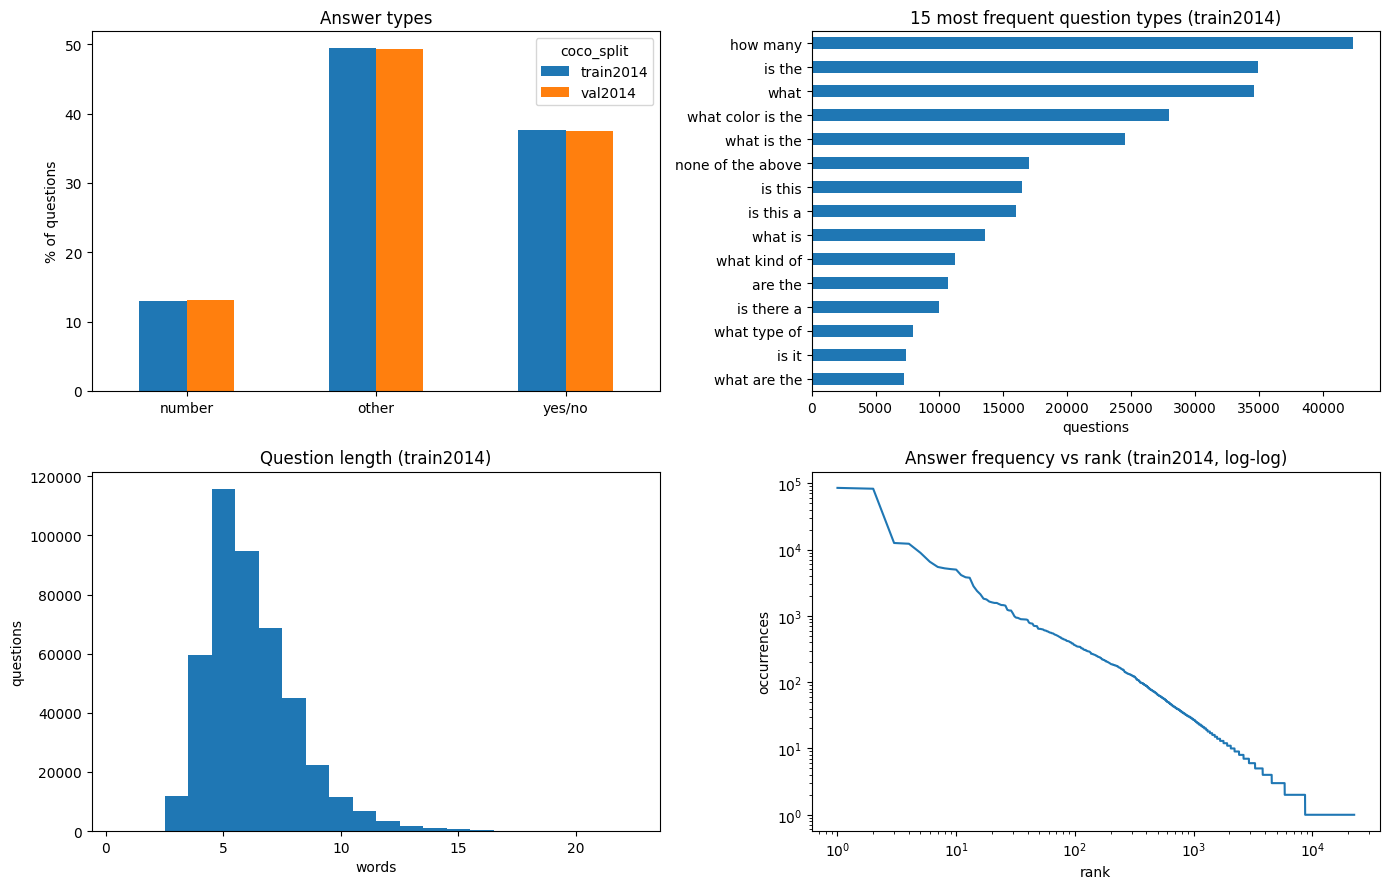

In [11]:
# 4.3 — Data exploration (full train2014 / val2014, before any subsampling)

# Display settings only, not hyperparameters: they change what is printed / plotted, never a result
TOP_N_QTYPES = 15
COVERAGE_TOPS = (10, 100, 1000, 3000)

train_df = vqa_df[vqa_df["coco_split"] == "train2014"]
val_df = vqa_df[vqa_df["coco_split"] == "val2014"]

# ---- 1. Answer types, per COCO split (is val2014, our test set, distributed like train2014?)
assert set(vqa_df["answer_type"]) == {"yes/no", "number", "other"}, "unexpected answer_type values"
answer_types = pd.crosstab(vqa_df["answer_type"], vqa_df["coco_split"], normalize="columns")
print("1. Answer types (% of the questions of each split)")
print((100 * answer_types).round(1).to_string())

# ---- 2. Question types (train2014)
qtype_counts = train_df["question_type"].value_counts()
top_share = qtype_counts.head(TOP_N_QTYPES).sum() / len(train_df)
print(f"\n2. {len(qtype_counts)} question types; the {TOP_N_QTYPES} most frequent cover {top_share:.1%} of train2014")
print(qtype_counts.head(5).to_string())

# ---- 3. Question length, in words (train2014)
q_len = train_df["question"].str.split().str.len()
print(f"\n3. Words per question: median = {q_len.median():.0f}, p90 = {q_len.quantile(0.9):.0f}, "
      f"p99 = {q_len.quantile(0.99):.0f}, max = {q_len.max()}")
# Each word gives at least 1 CLIP token, plus <start> and <end>: (words + 2) is a LOWER bound on the CLIP length.
surely_cut = (q_len + 2 > cfg.max_question_len).mean()
print(f"   Questions surely truncated at cfg.max_question_len = {cfg.max_question_len} CLIP tokens: {surely_cut:.3%}"
      "  (exact count in CLIP tokens: section 7)")

# ---- 4. Answers: long tail (train2014, raw multiple_choice_answer; normalization comes in 4.6)
ans_counts = train_df["multiple_choice_answer"].value_counts()
print(f"\n4. {len(ans_counts)} distinct answers, {(ans_counts == 1).sum()} of which appear only once")
for n in COVERAGE_TOPS:
    print(f"   top {n:>5} answers cover {ans_counts.head(n).sum() / len(train_df):.1%} of the questions")
a_len = train_df["multiple_choice_answer"].str.split().str.len()
print(f"   One-word answers: {(a_len == 1).mean():.1%}, longest: {a_len.max()} words"
      f"  (cfg.max_answer_len = {cfg.max_answer_len} Qwen tokens, checked in section 15)")

# ---- 5. Language prior: how far can we get WITHOUT looking at the image?
# Most frequent answer of each question type, fitted on train2014...
majority = (train_df.groupby("question_type")["multiple_choice_answer"]
            .agg(lambda s: s.value_counts().index[0]))
# ...evaluated on val2014 (exact match on multiple_choice_answer, NOT the VQA metric of 4.7).
# A question type absent from train gives NaN → counted as wrong.
hit = val_df["question_type"].map(majority) == val_df["multiple_choice_answer"]
yes_share = (train_df.loc[train_df["answer_type"] == "yes/no", "multiple_choice_answer"] == "yes").mean()
print(f"\n5. Language prior (no image): 'majority answer of the question type' → {hit.mean():.1%} exact match on val2014")
print((100 * hit.groupby(val_df["answer_type"]).mean()).round(1).to_string())
print(f"   Share of 'yes' among yes/no questions (train2014): {yes_share:.1%}")

# ---- Running example
ex_qtype = example_rows["question_type"].value_counts().index[0]
print(f'\nRunning example: question_type = "{ex_qtype}", '
      f'answer_type = {example_rows["answer_type"].value_counts().to_dict()}, '
      f'prior answer (no image) = "{majority[ex_qtype]}"')

# ---- Figure
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

(100 * answer_types).plot.bar(ax=axes[0, 0], rot=0)
axes[0, 0].set(title="Answer types", ylabel="% of questions", xlabel="")

qtype_counts.head(TOP_N_QTYPES)[::-1].plot.barh(ax=axes[0, 1])
axes[0, 1].set(title=f"{TOP_N_QTYPES} most frequent question types (train2014)", xlabel="questions", ylabel="")

axes[1, 0].hist(q_len, bins=np.arange(1, q_len.max() + 2) - 0.5)      # one bin per integer length
axes[1, 0].set(title="Question length (train2014)", xlabel="words", ylabel="questions")

axes[1, 1].loglog(np.arange(1, len(ans_counts) + 1), ans_counts.values)
axes[1, 1].set(title="Answer frequency vs rank (train2014, log-log)", xlabel="rank", ylabel="occurrences")

fig.tight_layout()
fig.savefig(cfg.path("fig", "4_3_exploration.png"), dpi=120, bbox_inches="tight")
plt.show()

### 4.4 Train / dev / test split by `image_id`

**Goal**: draw the images of each split and save their ID lists, so every later section works on exactly the same examples.

| Split | Source | Size | Role |
|---|---|---|---|
| train | train2014 | `cfg.n_train_images` | Training (section 18) |
| dev | train2014 | `cfg.n_dev_images` | Model selection, hyperparameters, oracle labels |
| test | val2014 | `cfg.n_test_images` | Final evaluation only (sections 19 – 20) |

**Concept: why split by image, not by question.** An image has about 5 questions. With a split by question, the same image would appear in train and in dev: the dev score would partly measure how well the model **remembers that image**, not how well it generalizes. With a split by `image_id`, no dev or test image is ever seen in training.

**Three less obvious choices:**

* **Nested subsets.** We shuffle the image pool once (with `cfg.seed`). Train takes the **start** of the permutation, dev takes the **end**. The DEBUG subset is therefore a strict **prefix** of the full subset: its 40 train images are among the full 10,000, and its dev images are among the full dev. What we debug on is part of what we will train on, and train and dev can never overlap, whatever the sizes.
* **Local generator** `np.random.default_rng(cfg.seed)`: the draw is the same whatever cells ran before. The global seed (3.5) would depend on how many random numbers were drawn earlier.
* **File name with the sizes.** `data_dir` is shared between DEBUG and full mode, so the file name contains the seed and the three sizes. A DEBUG split is never reloaded in full mode.

We only save **ID lists** here. The normalized DataFrame is saved in 4.8, once the answers are normalized.

In [12]:
# 4.4 — Train / dev / test split by image_id

def make_splits() -> dict:
    """Draws the image_ids of each split. Train and dev come from train2014, test from val2014."""
    rng = np.random.default_rng(cfg.seed)     # local generator: the draw does not depend on what ran before

    # np.sort first: the draw then depends only on the SET of images, not on the DataFrame row order
    train_pool = rng.permutation(np.sort(vqa_df.loc[vqa_df["coco_split"] == "train2014", "image_id"].unique()))
    test_pool = rng.permutation(np.sort(vqa_df.loc[vqa_df["coco_split"] == "val2014", "image_id"].unique()))

    n_tr, n_dev, n_te = cfg.n_train_images, cfg.n_dev_images, cfg.n_test_images
    assert n_tr + n_dev <= len(train_pool), "not enough train2014 images for train + dev"
    assert n_te <= len(test_pool), "not enough val2014 images for test"

    return {
        "train": train_pool[:n_tr].tolist(),                       # START of the permutation
        "dev":   train_pool[len(train_pool) - n_dev:].tolist(),    # END of the permutation → never overlaps train
        "test":  test_pool[:n_te].tolist(),
        "seed":  cfg.seed,
    }


# data_dir is shared between DEBUG and full → the sizes are part of the file name
split_file = cfg.path("data", f"splits_seed{cfg.seed}_train{cfg.n_train_images}"
                              f"_dev{cfg.n_dev_images}_test{cfg.n_test_images}.json")
SPLIT_IDS = load_or_compute(
    split_file,
    make_splits,
    save_fn=lambda obj, p: p.write_text(json.dumps(obj)),
    load_fn=lambda p: json.loads(p.read_text()),
)

# The subset as one DataFrame, with a `split` column.
# We filter on coco_split as well as image_id: each image_id is then looked up in the COCO split it was drawn from.
SPLIT_SOURCE = {"train": "train2014", "dev": "train2014", "test": "val2014"}
subset_df = pd.concat(
    [vqa_df[(vqa_df["coco_split"] == src) & vqa_df["image_id"].isin(SPLIT_IDS[split])].assign(split=split)
     for split, src in SPLIT_SOURCE.items()],
    ignore_index=True,
)

# Quick sanity checks (the full checks are in 4.9)
ids = {s: set(SPLIT_IDS[s]) for s in SPLIT_SOURCE}
assert not (ids["train"] & ids["dev"]), "train and dev share images"
assert len(ids["train"]) == cfg.n_train_images and len(ids["dev"]) == cfg.n_dev_images \
    and len(ids["test"]) == cfg.n_test_images, "a split does not have the expected number of images"

print()
show("subset_df", subset_df)
summary = subset_df.groupby("split", sort=False).agg(images=("image_id", "nunique"),
                                                      questions=("question_id", "size"))
summary["questions / image"] = (summary["questions"] / summary["images"]).round(2)
print(summary.to_string())

# Does the subset look like the full data? (very noisy in DEBUG: ~50 questions in dev / test)
types = pd.crosstab(subset_df["answer_type"], subset_df["split"], normalize="columns")[list(SPLIT_SOURCE)]
types["train2014 (full)"] = vqa_df.loc[vqa_df["coco_split"] == "train2014", "answer_type"].value_counts(normalize=True)
print("\nAnswer types (% of questions):")
print((100 * types).round(1).to_string())

# Running example: is "What color is the car?" in our subset?
in_subset = subset_df[subset_df["question"].str.lower() == "what color is the car?"]
print('\nRunning example: "What color is the car?" questions per split:',
      in_subset["split"].value_counts().reindex(list(SPLIT_SOURCE), fill_value=0).to_dict())

↩️  Reloaded: splits_seed42_train40_dev10_test10.json

subset_df                    len=285  type=DataFrame
       images  questions  questions / image
split                                      
train      40        173               4.32
dev        10         47               4.70
test       10         65               6.50

Answer types (% of questions):
split        train   dev  test  train2014 (full)
answer_type                                     
number        11.0  12.8  15.4              13.0
other         52.0  51.1  38.5              49.4
yes/no        37.0  36.2  46.2              37.6

Running example: "What color is the car?" questions per split: {'train': 0, 'dev': 0, 'test': 0}


### 4.5 Downloading the COCO 2014 images of the subset

**Goal**: put on the fast local disk (`cfg.image_dir`) **only** the images of our splits, not the whole of COCO 2014.

**Why image by image, not the official archive.** The train2014 archive holds all the train2014 images counted in 4.2 (several GB), and we need only `cfg.n_train_images + cfg.n_dev_images` of them. The COCO server also serves each image individually, under its official file name `COCO_<split>_<12-digit image_id>.jpg`.

**Where.** On `FAST_DIR`, not on Drive (see 3.1): reading thousands of small files from Drive is slow. On Colab, the images are therefore lost at the end of the session and re-downloaded at the next one. The cell is cheap to rerun, because it only fetches what is missing. The images do not depend on DEBUG: the DEBUG images are a subset of the full ones (4.4).

**Robustness**, same principle as 4.1:

* each image is written to `.tmp`, **fully decoded** with PIL (catches a truncated file or an HTML error page), then renamed to `.jpg`. A `.jpg` on disk is therefore always a valid image;
* a timeout, plus a few retries for network errors;
* if some images still fail, the cell stops with an `assert`. Rerunning it retries only the missing ones.

**Parallelism.** Downloading is *I/O-bound*: each thread mostly waits for the network, so Python threads are enough despite the GIL.

The cell ends with a **preview of section 5**: COCO images are often not square, and the CLIP preprocessing (resize the short side, then center crop) cuts off part of each image. We measure how much.

In [13]:
# 4.5 — Download only the COCO 2014 images of the subset
from concurrent.futures import ThreadPoolExecutor, as_completed
from PIL import Image

COCO_BASE_URL = "http://images.cocodataset.org"   # this host does not answer over HTTPS (checked), hence HTTP

# Runtime / network settings, not hyperparameters: they change how fast we download, never a result
N_DOWNLOAD_THREADS = 16
DOWNLOAD_TIMEOUT_S = 30
N_RETRIES = 3


def coco_image_path(coco_split: str, image_id: int) -> Path:
    """Official COCO 2014 file name, e.g. <image_dir>/train2014/COCO_train2014_000000057870.jpg"""
    return Path(cfg.image_dir) / coco_split / f"COCO_{coco_split}_{image_id:012d}.jpg"


def fetch_coco_image(coco_split: str, image_id: int):
    """Downloads one image if it is missing. Returns None on success, an error message otherwise."""
    path = coco_image_path(coco_split, image_id)
    if path.exists():
        return None
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name + ".tmp")
    url = f"{COCO_BASE_URL}/{coco_split}/{path.name}"

    err = None
    for attempt in range(1, N_RETRIES + 1):
        try:
            with urllib.request.urlopen(url, timeout=DOWNLOAD_TIMEOUT_S) as r, open(tmp, "wb") as f:
                shutil.copyfileobj(r, f)
            # Full decode: catches a truncated file, or an HTML error page saved as .jpg
            with Image.open(tmp) as im:
                im.load()
            tmp.replace(path)                     # the .jpg only appears once it is complete and valid
            return None
        except Exception as e:
            err = f"{coco_split}/{image_id}: {type(e).__name__}: {e}"
            time.sleep(attempt)                   # wait a bit longer after each failure
    tmp.unlink(missing_ok=True)
    return err


# Unique (coco_split, image_id) pairs of the subset
subset_images = list(subset_df[["coco_split", "image_id"]].drop_duplicates().itertuples(index=False, name=None))
missing = [(s, i) for s, i in subset_images if not coco_image_path(s, i).exists()]
print(f"{len(subset_images)} images in the subset, {len(missing)} to download")

errors = []
if missing:
    t0 = time.perf_counter()
    # Downloading is I/O-bound: threads wait on the network, so the GIL is not a bottleneck
    with ThreadPoolExecutor(max_workers=N_DOWNLOAD_THREADS) as pool:
        futures = [pool.submit(fetch_coco_image, s, i) for s, i in missing]
        for fut in tqdm(as_completed(futures), total=len(futures), desc="COCO images"):
            if (err := fut.result()) is not None:
                errors.append(err)
    print(f"⬇️  Done in {time.perf_counter() - t0:.1f} s")

# Rerunning the cell only retries the missing images
assert not errors, f"{len(errors)} images could not be downloaded, e.g.: {errors[:3]}"

# ---- What is on disk
paths = [coco_image_path(s, i) for s, i in subset_images]
assert all(p.exists() for p in paths), "some subset images are missing on disk"
sizes_kb = np.array([p.stat().st_size for p in paths]) / 1024
print(f"\nOn disk: {len(paths)} images, {sizes_kb.sum() / 1024:.1f} MB, {sizes_kb.mean():.0f} KB per image on average")

# Image sizes in pixels (Image.open only reads the header: fast)
wh = np.array([Image.open(p).size for p in paths])                 # (n_images, 2) = (width, height)
short, long = wh.min(axis=1), wh.max(axis=1)
print(f"Width:  median = {np.median(wh[:, 0]):.0f} px   Height: median = {np.median(wh[:, 1]):.0f} px")
print(f"Square images: {(short == long).mean():.1%}")
# Preview of section 5: resizing the short side to 224, then center-cropping 224×224, keeps a fraction short/long
# of the image area. The rest is cut off and CLIP never sees it.
print(f"Share of the image area cut off by the center crop: mean = {(1 - short / long).mean():.1%}, "
      f"max = {(1 - short / long).max():.1%}")

60 images in the subset, 0 to download

On disk: 60 images, 9.2 MB, 156 KB per image on average
Width:  median = 640 px   Height: median = 480 px
Square images: 3.3%
Share of the image area cut off by the center crop: mean = 28.3%, max = 51.7%


#### 4.5b Choosing the running-example image

**Goal**: fix the image of the running example, "What color is the car?" (section 1.5), and download it.

As expected, this question is not in the DEBUG subset (4.4). The running example is used **for display only** (shapes, heatmaps, selected patches), never for training or evaluation. Its image therefore does not have to belong to a split, and we download it on top of the subset.

**How we choose.** Among the questions that are exactly "What color is the car?" with `multiple_choice_answer = "red"`, we keep the ones where the most annotators agree on "red" (an unambiguous example). Ties are broken by `question_id`, so the choice is deterministic. The cell displays the candidates. The first one is the default, and you can pick another by setting `EXAMPLE_QID` to the `question_id` shown in its title.

The resulting `EXAMPLE` dictionary (question, 10 answers, image path) is reused in every section.

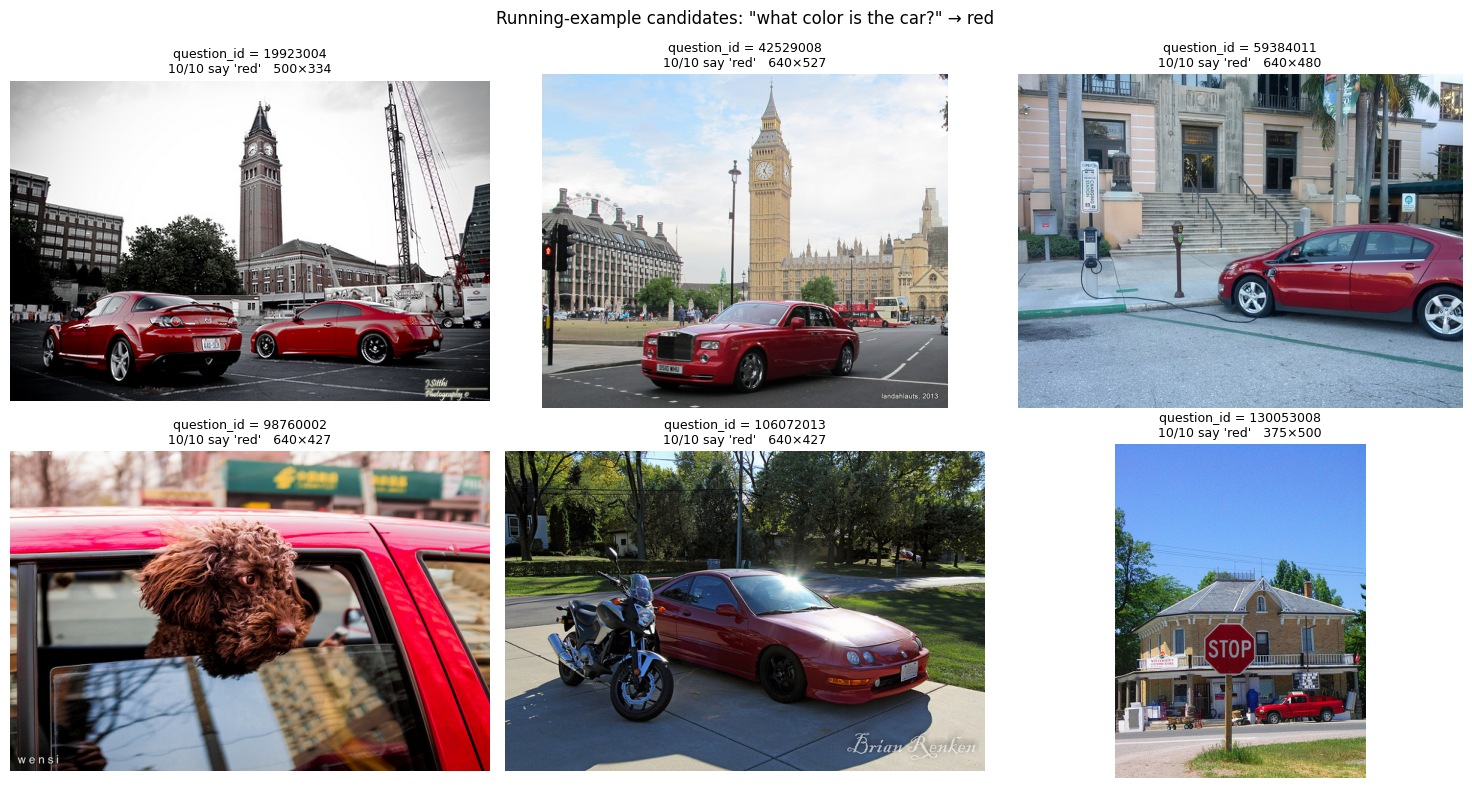

Chosen: question_id = 19923004  (val2014, image_id = 19923)
   in our splits: no → display only
   question      : What color is the car?
   10 answers    : ['red', 'red', 'red', 'red', 'red', 'red', 'red', 'red', 'red', 'red']
   multiple_choice_answer = 'red', answer_type = other

The 5 questions on this image:
                                question multiple_choice_answer
      How many cars are in this picture?                      2
What color are the cars in this picture?                    red
                 What make are the cars?                 nissan
              What is in the background?            clock tower
                  What color is the car?                    red

raw image (H×W×3)            (334, 500, 3)      uint8     cpu


In [14]:
# 4.5b — Choosing the running-example image ("What color is the car?")

# Definition of the running example (PLAN.md), not hyperparameters
EXAMPLE_QUESTION = "what color is the car?"     # compared in lower case
EXAMPLE_ANSWER = "red"
N_CANDIDATES = 6                                # display only
EXAMPLE_QID = None    # ← None = first candidate. Put a question_id from the grid below to choose another image.

# Candidates: exactly the running-example question, answered "red", sorted by agreement among the 10 annotators
cands = vqa_df[(vqa_df["question"].str.lower() == EXAMPLE_QUESTION)
               & (vqa_df["multiple_choice_answer"] == EXAMPLE_ANSWER)].copy()
cands["n_agree"] = cands["answers"].map(lambda answers: sum(a == EXAMPLE_ANSWER for a in answers))
cands = cands.sort_values(["n_agree", "question_id"], ascending=[False, True]).head(N_CANDIDATES)
assert len(cands) > 0, "no candidate for the running example"

# Download the candidate images (same function as for the subset)
errors = [e for s, i in zip(cands["coco_split"], cands["image_id"]) if (e := fetch_coco_image(s, i)) is not None]
assert not errors, f"candidate images could not be downloaded: {errors}"

# Grid of candidates
n_cols = 3
n_rows = math.ceil(len(cands) / n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 4 * n_rows), squeeze=False)
for ax in axes.flat:
    ax.axis("off")
for ax, row in zip(axes.flat, cands.itertuples()):
    with Image.open(coco_image_path(row.coco_split, row.image_id)) as im:
        ax.imshow(im)
        ax.set_title(f"question_id = {row.question_id}\n{row.n_agree}/10 say '{EXAMPLE_ANSWER}'   {im.width}×{im.height}",
                     fontsize=9)
fig.suptitle(f'Running-example candidates: "{EXAMPLE_QUESTION}" → {EXAMPLE_ANSWER}')
fig.tight_layout()
plt.show()

# The chosen example
qid = EXAMPLE_QID if EXAMPLE_QID is not None else int(cands["question_id"].iloc[0])
EXAMPLE = vqa_df.loc[vqa_df["question_id"] == qid].iloc[0].to_dict()
assert fetch_coco_image(EXAMPLE["coco_split"], EXAMPLE["image_id"]) is None, "running-example image download failed"
EXAMPLE["image_path"] = coco_image_path(EXAMPLE["coco_split"], EXAMPLE["image_id"])

in_split = subset_df.loc[subset_df["question_id"] == qid, "split"].tolist()
print(f"Chosen: question_id = {qid}  ({EXAMPLE['coco_split']}, image_id = {EXAMPLE['image_id']})")
print(f"   in our splits: {in_split[0] if in_split else 'no → display only'}")
print(f"   question      : {EXAMPLE['question']}")
print(f"   10 answers    : {EXAMPLE['answers']}")
print(f"   multiple_choice_answer = {EXAMPLE['multiple_choice_answer']!r}, answer_type = {EXAMPLE['answer_type']}")

# The other questions asked about the same image (useful for "one image, several questions", section 21)
same_image = vqa_df[(vqa_df["coco_split"] == EXAMPLE["coco_split"]) & (vqa_df["image_id"] == EXAMPLE["image_id"])]
print(f"\nThe {len(same_image)} questions on this image:")
print(same_image[["question", "multiple_choice_answer"]].to_string(index=False))

# First line of the running-example table: the raw image, H×W×3
example_image = Image.open(EXAMPLE["image_path"]).convert("RGB")
print()
show("raw image (H×W×3)", torch.from_numpy(np.array(example_image)))

### 4.6 Official answer normalization

**Goal**: compare answers the way the official evaluation does. Without normalization, "Two", "two" and "2" would be three different answers.

The rules below are copied **verbatim** from the official script ([`GT-Vision-Lab/VQA`](https://github.com/GT-Vision-Lab/VQA), `PythonEvaluationTools/vqaEvaluation/vqaEval.py`), including their quirks. Our numbers stay comparable to published VQAv2 results only if we use the same rules.

| Step | Rule | Example |
|---|---|---|
| 1 | `\n` and `\t` → space, then `strip()` | `"  yes\n"` → `"yes"` |
| 2 | **Punctuation** (21 symbols): deleted if it touches a space, or if the text contains a number like `1,000`; otherwise replaced by a space | `"black, white"` → `"black white"`, `"black/white"` → `"black white"` |
| 3 | **Periods** deleted, unless followed by a digit | `"car."` → `"car"`, but `"3.5"` stays |
| 4 | **Lower case**, then **number words → digits** (zero to ten, and also `none` → `0`) | `"Two"` → `"2"` |
| 5 | **Articles** removed (`a`, `an`, `the`) | `"a red car"` → `"red car"` |
| 6 | **Contractions** restored | `"dont"` → `"don't"` |

**Two quirks we keep on purpose:**

* `none` → `0`: "How many dogs?" → "none" counts as "0". This is a choice of the official script.
* The script passes `re.UNICODE` (= 32) where `re.sub` expects its `count` argument: at most 32 periods are removed. This never matters for a VQA answer, but we reproduce it rather than fix it.

The rest of the official logic (normalization is only applied when the annotators **disagree**) belongs to the metric: it is in 4.7.

The cell prints a few hand-picked examples, then measures how many raw answers of train2014 normalization actually changes.

In [15]:
# 4.6 — Official answer normalization (rules copied verbatim from vqaEval.py)
import re

# ---- Official tables, copied verbatim (including the capitalized keys, which can never match after lower())
CONTRACTIONS = {
    "aint": "ain't", "arent": "aren't", "cant": "can't", "couldve": "could've", "couldnt": "couldn't",
    "couldn'tve": "couldn't've", "couldnt've": "couldn't've", "didnt": "didn't", "doesnt": "doesn't", "dont": "don't",
    "hadnt": "hadn't", "hadnt've": "hadn't've", "hadn'tve": "hadn't've", "hasnt": "hasn't", "havent": "haven't",
    "hed": "he'd", "hed've": "he'd've", "he'dve": "he'd've", "hes": "he's", "howd": "how'd", "howll": "how'll",
    "hows": "how's", "Id've": "I'd've", "I'dve": "I'd've", "Im": "I'm", "Ive": "I've", "isnt": "isn't", "itd": "it'd",
    "itd've": "it'd've", "it'dve": "it'd've", "itll": "it'll", "let's": "let's", "maam": "ma'am", "mightnt": "mightn't",
    "mightnt've": "mightn't've", "mightn'tve": "mightn't've", "mightve": "might've", "mustnt": "mustn't",
    "mustve": "must've", "neednt": "needn't", "notve": "not've", "oclock": "o'clock", "oughtnt": "oughtn't",
    "ow's'at": "'ow's'at", "'ows'at": "'ow's'at", "'ow'sat": "'ow's'at", "shant": "shan't", "shed've": "she'd've",
    "she'dve": "she'd've", "she's": "she's", "shouldve": "should've", "shouldnt": "shouldn't",
    "shouldnt've": "shouldn't've", "shouldn'tve": "shouldn't've", "somebody'd": "somebodyd",
    "somebodyd've": "somebody'd've", "somebody'dve": "somebody'd've", "somebodyll": "somebody'll",
    "somebodys": "somebody's", "someoned": "someone'd", "someoned've": "someone'd've", "someone'dve": "someone'd've",
    "someonell": "someone'll", "someones": "someone's", "somethingd": "something'd", "somethingd've": "something'd've",
    "something'dve": "something'd've", "somethingll": "something'll", "thats": "that's", "thered": "there'd",
    "thered've": "there'd've", "there'dve": "there'd've", "therere": "there're", "theres": "there's", "theyd": "they'd",
    "theyd've": "they'd've", "they'dve": "they'd've", "theyll": "they'll", "theyre": "they're", "theyve": "they've",
    "twas": "'twas", "wasnt": "wasn't", "wed've": "we'd've", "we'dve": "we'd've", "weve": "we've", "werent": "weren't",
    "whatll": "what'll", "whatre": "what're", "whats": "what's", "whatve": "what've", "whens": "when's",
    "whered": "where'd", "wheres": "where's", "whereve": "where've", "whod": "who'd", "whod've": "who'd've",
    "who'dve": "who'd've", "wholl": "who'll", "whos": "who's", "whove": "who've", "whyll": "why'll", "whyre": "why're",
    "whys": "why's", "wont": "won't", "wouldve": "would've", "wouldnt": "wouldn't", "wouldnt've": "wouldn't've",
    "wouldn'tve": "wouldn't've", "yall": "y'all", "yall'll": "y'all'll", "y'allll": "y'all'll",
    "yall'd've": "y'all'd've", "y'alld've": "y'all'd've", "y'all'dve": "y'all'd've", "youd": "you'd",
    "youd've": "you'd've", "you'dve": "you'd've", "youll": "you'll", "youre": "you're", "youve": "you've",
}
MANUAL_MAP = {"none": "0", "zero": "0", "one": "1", "two": "2", "three": "3", "four": "4",
              "five": "5", "six": "6", "seven": "7", "eight": "8", "nine": "9", "ten": "10"}
ARTICLES = ["a", "an", "the"]
# A "." NOT followed by a digit. (The first group "(?!<=\d)" is the official pattern: a malformed
# look-behind that has no effect in practice. We keep it to stay identical.)
PERIOD_STRIP = re.compile(r"(?!<=\d)(\.)(?!\d)")
COMMA_STRIP = re.compile(r"(\d)(\,)(\d)")          # a "," between two digits, as in "1,000"
PUNCT = [";", r"/", "[", "]", '"', "{", "}", "(", ")", "=", "+", "\\", "_", "-", ">", "<", "@", "`", ",", "?", "!"]


def process_punctuation(text: str) -> str:
    """Official processPunctuation."""
    out = text
    for p in PUNCT:
        # Symbol next to a space, or text containing a number like "1,000" → deleted. Otherwise → a space.
        # Note: the test is done on the ORIGINAL text, the replacement on the current one (as in the official code).
        if (p + " " in text or " " + p in text) or (re.search(COMMA_STRIP, text) is not None):
            out = out.replace(p, "")
        else:
            out = out.replace(p, " ")
    # Official quirk: re.UNICODE (= 32) is passed as `count` → at most 32 periods removed
    return PERIOD_STRIP.sub("", out, count=int(re.UNICODE))


def process_digit_article(text: str) -> str:
    """Official processDigitArticle: lower case, number words → digits, articles removed, contractions restored."""
    words = []
    for w in text.lower().split():
        w = MANUAL_MAP.get(w, w)
        if w not in ARTICLES:
            words.append(w)
    words = [CONTRACTIONS.get(w, w) for w in words]
    return " ".join(words)


def clean_whitespace(text: str) -> str:
    """Step applied by the official script to EVERY answer, before anything else."""
    return text.replace("\n", " ").replace("\t", " ").strip()


def normalize_answer(text: str) -> str:
    """The full chain: whitespace → punctuation → digits / articles / contractions."""
    return process_digit_article(process_punctuation(clean_whitespace(text)))


# ---- 1. Hand-picked examples (the expected outputs are tested in 4.9)
demo = ["Two", "a red car.", "3.5", "1,000", "black, white", "black/white", "dont", "None", "  Yes!\n", "the dog's"]
print("1. Examples")
for s in demo:
    print(f"   {s!r:<16} → {normalize_answer(s)!r}")

# ---- 2. On real data: all the raw human answers of train2014 (10 per question)
answer_freq = vqa_df.loc[vqa_df["coco_split"] == "train2014", "answers"].explode().value_counts()
normalized = pd.Series({a: normalize_answer(a) for a in answer_freq.index})      # one call per DISTINCT answer
is_changed = normalized.index.to_numpy() != normalized.to_numpy()
print(f"\n2. train2014: {answer_freq.sum()} human answers, {len(answer_freq)} distinct")
print(f"   distinct answers changed by normalization: {is_changed.sum()} ({is_changed.mean():.1%})")
print(f"   share of all answer occurrences changed  : {answer_freq[is_changed].sum() / answer_freq.sum():.1%}")
print(f"   distinct answers after normalization     : {normalized.nunique()}")
print("   Most frequent answers changed by normalization:")
top_changed = pd.DataFrame({"raw": normalized.index[is_changed], "normalized": normalized.to_numpy()[is_changed],
                            "occurrences": answer_freq.to_numpy()[is_changed]})
print(top_changed.head(10).to_string(index=False))

# ---- Running example
print(f"\nRunning example, 10 answers normalized: {[normalize_answer(a) for a in EXAMPLE['answers']]}")

1. Examples
   'Two'            → '2'
   'a red car.'     → 'red car'
   '3.5'            → '3.5'
   '1,000'          → '1000'
   'black, white'   → 'black white'
   'black/white'    → 'black white'
   'dont'           → "don't"
   'None'           → '0'
   '  Yes!\n'       → 'yes'
   "the dog's"      → "dog's"

2. train2014: 4437570 human answers, 162496 distinct
   distinct answers changed by normalization: 20641 (12.7%)
   share of all answer occurrences changed  : 1.2%
   distinct answers after normalization     : 157463
   Most frequent answers changed by normalization:
         raw  normalized  occurrences
        none           0        10570
      no one        no 1         1818
     one way       1 way          527
           a                      401
one on right  1 on right          385
 one on left   1 on left          317
black, white black white          289
           ?                      268
     t-shirt     t shirt          253
         n/a           n          252


### 4.7 The official VQA Accuracy

**Goal**: score a predicted answer against the 10 human answers, exactly like the official script.

**Concept: a "soft" metric.** Humans do not all give the same answer ("red" / "dark red" / "maroon"). An answer is considered fully correct if **at least 3 annotators** gave it. To make the score robust to the choice of annotators, it is averaged over the **10 subsets of 9 annotators** (leave one out):

$$
\mathrm{Acc}(a) = \frac{1}{10} \sum_{i=1}^{10} \min\!\left(1,\ \frac{\#\{\, j \neq i : a_j = a \,\}}{3}\right)
$$

If $n$ of the 10 annotators gave answer $a$: in the $n$ subsets that leave out one of them, $n-1$ matches remain; in the other $10-n$ subsets, all $n$ matches remain. So

$$
\mathrm{Acc}(n) = \frac{n \cdot \min\!\left(1, \frac{n-1}{3}\right) + (10 - n) \cdot \min\!\left(1, \frac{n}{3}\right)}{10}
$$

Worked example, $n = 2$ (2 annotators out of 10 agree with us): $\frac{2 \cdot \frac13 + 8 \cdot \frac23}{10} = \frac{18}{30} = 0.6$. Computed by hand the same way: $n = 1 \to 0.3$, $n = 3 \to 0.9$, $n \ge 4 \to 1$. These values are tested in 4.9.

**The official quirk: normalization only when annotators disagree.** The script applies the 4.6 normalization (to the prediction **and** to the 10 answers) only if the 10 answers are not all identical. When they are unanimous, the prediction is compared to the **raw** string: "Red" against ten "red" scores **0**. We reproduce this exactly. Consequence for us: the model must produce answers **in the dataset's format** (lower case, digits…), which is why the training target (4.8) is the raw `multiple_choice_answer`, not a re-normalized version.

The cell prints the score table as a function of $n$ (computed by the function, not written by hand), then scores a few candidate predictions on the running example.

In [16]:
# 4.7 — Official VQA Accuracy (replica of VQAEval.evaluate in vqaEval.py)

def vqa_accuracy(pred: str, gt_answers: list) -> float:
    """VQA accuracy of ONE prediction against the human answers (10 in VQAv2). Returns a value in [0, 1]."""
    gts = [clean_whitespace(a) for a in gt_answers]
    res = clean_whitespace(pred)

    # Official quirk: normalization (4.6) only when the annotators do NOT all agree
    if len(set(gts)) > 1:
        gts = [process_digit_article(process_punctuation(a)) for a in gts]
        res = process_digit_article(process_punctuation(res))

    # Leave-one-out: for each annotator i, count the matches among the 9 others
    accs = []
    for i in range(len(gts)):
        others = gts[:i] + gts[i + 1:]
        n_match = sum(a == res for a in others)
        accs.append(min(1.0, n_match / 3))
    return sum(accs) / len(accs)


def vqa_accuracy_batch(preds, gt_answers_list) -> np.ndarray:
    """Vectorized over questions: one score per (prediction, list of 10 answers) pair."""
    return np.array([vqa_accuracy(p, g) for p, g in zip(preds, gt_answers_list)])


# ---- 1. Score as a function of n = number of annotators (out of 10) who gave our answer
# The other 10 - n annotators give distinct answers, so the "disagreement" branch is used (except n = 10).
print("1. Score vs number of annotators who agree with the prediction")
for n in range(0, 11):
    gts = ["red"] * n + [f"other{j}" for j in range(10 - n)]
    print(f"   n = {n:>2}  →  {vqa_accuracy('red', gts):.3f}")

# ---- 2. Running example: a few candidate predictions
print(f"\n2. Running example, answers = {EXAMPLE['answers']}")
example_preds = ["red", "Red", "red.", "dark red", "white", "the red one"]
scores = vqa_accuracy_batch(example_preds, [EXAMPLE["answers"]] * len(example_preds))
unanimous = len(set(clean_whitespace(a) for a in EXAMPLE["answers"])) == 1
print(f"   unanimous annotators: {unanimous}  → normalization {'NOT ' if unanimous else ''}applied")
for p, s in zip(example_preds, scores):
    print(f"   {p!r:<14} → {s:.3f}")

1. Score vs number of annotators who agree with the prediction
   n =  0  →  0.000
   n =  1  →  0.300
   n =  2  →  0.600
   n =  3  →  0.900
   n =  4  →  1.000
   n =  5  →  1.000
   n =  6  →  1.000
   n =  7  →  1.000
   n =  8  →  1.000
   n =  9  →  1.000
   n = 10  →  1.000

2. Running example, answers = ['red', 'red', 'red', 'red', 'red', 'red', 'red', 'red', 'red', 'red']
   unanimous annotators: True  → normalization NOT applied
   'red'          → 1.000
   'Red'          → 0.000
   'red.'         → 0.000
   'dark red'     → 0.000
   'white'        → 0.000
   'the red one'  → 0.000


### 4.8 Training target and saving the subset

**Goal**: choose the single string the model learns to generate for each question, then save the subset table that sections 6 and 18 – 20 reload.

**The target: `multiple_choice_answer`.** It is the most frequent of the 10 human answers (as defined by VQAv2). The LLM is trained with a cross-entropy on **one** answer string (section 2.3), so we need a single answer per question. This is the standard choice for generative VQA models. Alternatives (drawing one of the 10 answers at random, or soft targets over an answer vocabulary) are possible, but they are out of scope here.

**Why the raw target, not a normalized one.** Consider the two cases of the official metric (4.7):

* **annotators disagree**: the prediction is normalized before comparison, so the raw and normalized targets score the same;
* **annotators are unanimous**: the prediction is compared to the **raw** string. A model trained on a normalized target could produce `"2"` where the 10 annotators wrote `"two"`, and score 0.

The raw target is therefore never worse. The cell measures how often each case happens.

**Concept: the ceiling of the target.** Even a perfect model that always outputs `multiple_choice_answer` does not get 100%, because annotators disagree. Its score is the **ceiling** of what our training can achieve. We store it per question (`oracle_acc`) and will compare our models to it in section 20.

**Saving.** One row per question, in `data_dir`, with the same seed and sizes in the file name as the split (4.4). We save the raw `answers`: the metric normalizes them itself when it has to.

In [17]:
# 4.8 — Training target and saving the subset table
SUBSET_COLUMNS = ["split", "coco_split", "image_id", "question_id", "question", "question_type", "answer_type",
                  "answers", "target", "oracle_acc"]


def build_subset_table() -> pd.DataFrame:
    df = subset_df.copy()
    # Same whitespace cleaning as the official script, nothing else (see the markdown above)
    df["target"] = df["multiple_choice_answer"].map(clean_whitespace)
    # Score of a perfect model that always outputs the target = ceiling of the training
    df["oracle_acc"] = vqa_accuracy_batch(df["target"], df["answers"])
    return df[SUBSET_COLUMNS].reset_index(drop=True)


# Same seed and sizes as the split file of 4.4: "splits_..." → "subset_..."
subset_file = cfg.path("data", split_file.stem.replace("splits_", "subset_") + ".pkl")
data_df = load_or_compute(subset_file, build_subset_table,
                          save_fn=lambda obj, p: obj.to_pickle(p), load_fn=pd.read_pickle)
print()
show("data_df", data_df)


# ---- 1. Raw vs normalized target: how often does it matter?
def target_stats(df: pd.DataFrame) -> dict:
    target = df["multiple_choice_answer"].map(clean_whitespace)
    cache = {t: normalize_answer(t) for t in target.unique()}          # one call per distinct target
    changed = target.map(cache) != target
    unanimous = df["answers"].map(lambda answers: len(set(clean_whitespace(a) for a in answers)) == 1)
    return {
        "questions": len(df),
        "target changed by normalization": f"{changed.mean():.2%}",
        "unanimous annotators": f"{unanimous.mean():.1%}",
        "unanimous AND target changed (normalized target would score 0)": f"{(unanimous & changed).mean():.2%}",
    }


stats = pd.DataFrame({
    "subset": target_stats(subset_df),
    "train2014 (full)": target_stats(vqa_df[vqa_df["coco_split"] == "train2014"]),
})
print("\n1. Raw vs normalized target")
print(stats.to_string())

# ---- 2. Ceiling of the target (oracle), per split and per answer type
print("\n2. Ceiling: VQA accuracy of a model that always outputs the target (%)")
ceiling = data_df.pivot_table(index="answer_type", columns="split", values="oracle_acc", aggfunc="mean")
ceiling.loc["all"] = data_df.groupby("split")["oracle_acc"].mean()
print((100 * ceiling[list(SPLIT_SOURCE)]).round(1).to_string())

# ---- 3. Target length (the exact length in Qwen tokens is checked in section 15)
target_words = data_df["target"].str.split().str.len()
print(f"\n3. Target length: {(target_words == 1).mean():.1%} one-word targets, longest = {target_words.max()} words")
print(f"   e.g. {data_df.loc[target_words.idxmax(), 'target']!r}")

# ---- Running example
ex_target = clean_whitespace(EXAMPLE["multiple_choice_answer"])
print(f"\nRunning example: target = {ex_target!r}, ceiling = {vqa_accuracy(ex_target, EXAMPLE['answers']):.3f}")

↩️  Reloaded: subset_seed42_train40_dev10_test10.pkl

data_df                      len=285  type=DataFrame

1. Raw vs normalized target
                                                               subset train2014 (full)
questions                                                         285           443757
target changed by normalization                                 1.05%            0.74%
unanimous annotators                                            28.8%            33.4%
unanimous AND target changed (normalized target would score 0)  0.00%            0.02%

2. Ceiling: VQA accuracy of a model that always outputs the target (%)
split        train    dev   test
answer_type                     
number        98.4  100.0   93.0
other         96.0   88.3   94.0
yes/no       100.0  100.0  100.0
all           97.7   94.0   96.6

3. Target length: 93.0% one-word targets, longest = 5 words
   e.g. 'delicious hand-crafted natural ice cream'

Running example: target = 'red', ceiling = 1.0

### 4.9 Section 4 checks

1. **Normalization**: hand-computed cases (one per rule of 4.6).
2. **VQA Accuracy**: hand-computed cases. The score as a function of $n$ ($0, 0.3, 0.6, 0.9, 1$), the unanimous case without normalization, and the normalization branch (number words, articles, punctuation).
3. **Splits**: no image shared between train, dev and test, the right COCO split for each, the sizes from `cfg`, every question of a selected image kept, and the same draw when `make_splits()` is called again.
4. **Images**: every subset image and the running-example image are on disk.
5. **Saved table**: reloading the file gives exactly the same table, and every target is a non-empty string.
6. **Ceiling**: a target that appears among the 10 answers scores at least $0.3$ (the $n = 1$ case). This is a mathematical property of the metric, so a failure here would mean a bug in `vqa_accuracy`.

In [18]:
# 4.9 — Section 4 checks
checks = {}

# ---- 1. Normalization: hand-computed expected outputs
NORM_CASES = {
    "Two dogs": "2 dogs",            # lower case + number word → digit
    "a red car.": "red car",         # final period removed, article removed
    "3.5": "3.5",                    # a period followed by a digit is kept
    "1,000": "1000",                 # text contains digit,digit → the comma is deleted (not a space)
    "black, white": "black white",   # "," touches a space → deleted
    "black/white": "black white",    # isolated "/" → replaced by a space
    "dont": "don't",                 # contraction restored
    "None": "0",                     # official quirk: none → 0
    "  Yes!\n": "yes",               # whitespace, "!" → space, lower case
}
bad = {s: (normalize_answer(s), exp) for s, exp in NORM_CASES.items() if normalize_answer(s) != exp}
checks["normalization: hand-computed cases"] = not bad
if bad:
    print("Normalization mismatches (got, expected):", bad)


# ---- 2. VQA Accuracy: hand-computed expected scores
def gt_with(n: int, answer: str = "red") -> list:
    """10 answers: n annotators gave `answer`, the others gave distinct other answers."""
    return [answer] * n + [f"other{j}" for j in range(10 - n)]


ACC_CASES = [
    # (prediction, 10 answers, expected score, why)
    *[("red", gt_with(n), exp, f"n = {n}") for n, exp in [(0, 0.0), (1, 0.3), (2, 0.6), (3, 0.9), (4, 1.0), (9, 1.0)]],
    ("red", ["red"] * 10, 1.0, "unanimous, same string"),
    ("Red", ["red"] * 10, 0.0, "unanimous → no normalization (official quirk)"),
    ("Red", ["red"] * 9 + ["dark red"], 1.0, "disagreement → normalized, n = 9"),
    ("Two", ["2"] * 3 + ["3"] * 7, 0.9, "number word → digit, n = 3"),
    ("the dog", ["dog"] * 2 + ["cat"] * 8, 0.6, "article removed, n = 2"),
    ("yes!", ["yes"] * 5 + ["no"] * 5, 1.0, "punctuation removed, n = 5"),
    ("blue", ["red"] * 10, 0.0, "wrong answer"),
]
bad = [(why, vqa_accuracy(p, g), exp) for p, g, exp, why in ACC_CASES if not math.isclose(vqa_accuracy(p, g), exp, abs_tol=1e-9)]
checks["VQA accuracy: hand-computed cases"] = not bad
if bad:
    print("VQA accuracy mismatches (case, got, expected):", bad)

# ---- 3. Splits
images = {s: set(data_df.loc[data_df["split"] == s, ["coco_split", "image_id"]].itertuples(index=False, name=None))
          for s in SPLIT_SOURCE}
raw_ids = {s: {i for _, i in images[s]} for s in SPLIT_SOURCE}
checks["no image shared between train / dev / test"] = (
    not (images["train"] & images["dev"]) and not (images["train"] & images["test"]) and not (images["dev"] & images["test"])
)
# COCO image_ids are unique across train2014 and val2014, so the raw ids must be disjoint too
checks["no image_id shared between train / dev / test"] = (
    not (raw_ids["train"] & raw_ids["dev"]) and not (raw_ids["train"] & raw_ids["test"]) and not (raw_ids["dev"] & raw_ids["test"])
)
checks["train / dev from train2014, test from val2014"] = all(
    {c for c, _ in images[s]} == {SPLIT_SOURCE[s]} for s in SPLIT_SOURCE
)
checks["split sizes match cfg"] = (
    len(images["train"]), len(images["dev"]), len(images["test"])
) == (cfg.n_train_images, cfg.n_dev_images, cfg.n_test_images)
n_questions_full = vqa_df.groupby(["coco_split", "image_id"]).size()
n_questions_subset = data_df.groupby(["coco_split", "image_id"]).size()
checks["every question of a selected image is kept"] = n_questions_subset.eq(
    n_questions_full.loc[n_questions_subset.index]).all()
checks["question_id unique in the subset"] = data_df["question_id"].is_unique
checks["make_splits() is deterministic (same as the file)"] = make_splits() == SPLIT_IDS

# ---- 4. Images on disk
checks["all subset images on disk"] = all(
    coco_image_path(c, i).exists() for s in SPLIT_SOURCE for c, i in images[s]
)
checks["running-example image on disk"] = Path(EXAMPLE["image_path"]).exists()

# ---- 5. Saved table
reloaded = pd.read_pickle(subset_file)
checks["saved table reloads identically"] = (
    reloaded.drop(columns="answers").equals(data_df.drop(columns="answers"))
    and reloaded["answers"].tolist() == data_df["answers"].tolist()
)
checks["every target is a non-empty string"] = data_df["target"].map(lambda t: isinstance(t, str) and len(t) > 0).all()
checks["10 answers per question"] = data_df["answers"].map(len).eq(10).all()

# ---- 6. Ceiling
target_in_answers = [t in [clean_whitespace(a) for a in answers] for t, answers in zip(data_df["target"], data_df["answers"])]
target_in_answers = np.array(target_in_answers)
checks["oracle_acc in [0, 1]"] = data_df["oracle_acc"].between(0, 1).all()
checks["target among the answers → oracle_acc ≥ 0.3"] = (data_df.loc[target_in_answers, "oracle_acc"] >= 0.3 - 1e-9).all()
print(f"Information: target found among the 10 raw answers for {target_in_answers.mean():.1%} of the questions")

# ---- Summary
print()
for name, ok in checks.items():
    print(f"{'✅' if ok else '❌'} {name}")
assert all(checks.values()), "A section 4 check failed: do not move on to section 5."
print("\nSection 4 validated → we can move on to section 5.")

Information: target found among the 10 raw answers for 100.0% of the questions

✅ normalization: hand-computed cases
✅ VQA accuracy: hand-computed cases
✅ no image shared between train / dev / test
✅ no image_id shared between train / dev / test
✅ train / dev from train2014, test from val2014
✅ split sizes match cfg
✅ every question of a selected image is kept
✅ question_id unique in the subset
✅ make_splits() is deterministic (same as the file)
✅ all subset images on disk
✅ running-example image on disk
✅ saved table reloads identically
✅ every target is a non-empty string
✅ 10 answers per question
✅ oracle_acc in [0, 1]
✅ target among the answers → oracle_acc ≥ 0.3

Section 4 validated → we can move on to section 5.


## Section 5. Image preprocessing

**Goal**: understand what CLIP actually sees. The ViT never receives the COCO photo itself: it receives a 3×224×224 tensor produced by a fixed preprocessing pipeline. Everything the selector can choose from (section 9 onward) comes from this tensor.

| Subsection | Role |
|---|---|
| 5.1 | Apply the `CLIPImageProcessor` (resize, center crop, normalize), and reproduce it by hand |
| 5.2 | Original image next to the cropped image: what the crop removes |
| 5.3 | Overlay the 14×14 patch grid: one 16×16 patch = one visual token |
| 5.4 | Section checks |

### 5.1 The CLIP preprocessing pipeline

**Goal**: turn the raw running-example image (H×W×3, `uint8`) into the tensor the ViT expects (3×224×224, `float32`).

The `CLIPImageProcessor` of `cfg.clip_name` applies four steps, always the same ones CLIP was trained with:

| Step | Operation | Running example (500×334) |
|---|---|---|
| 1 | **Resize** the *short* side to 224 (bicubic), keeping the aspect ratio | 500×334 → 335×224 |
| 2 | **Center crop** 224×224 | the left and right edges are cut off |
| 3 | **Rescale** `uint8` [0, 255] → [0, 1] (× 1/255) | |
| 4 | **Normalize** per channel: $x_c \leftarrow (x_c - \mu_c) / \sigma_c$ | $\mu, \sigma$ = CLIP's training statistics |

**Concept: why normalize with fixed constants.** $\mu$ and $\sigma$ are the mean and standard deviation of each RGB channel over CLIP's **training set**, not over our image. The ViT's first layer learned its weights on inputs with that distribution, so we must give it inputs on the same scale. Consequence: the mean is close to 0 **on average over many images**, not for each image. A bright or reddish photo has a positive mean. Section 5.4 checks the mean over the whole subset.

**Layout change.** PIL / NumPy store images as H×W×C (channels last), PyTorch convolutions expect C×H×W (channels first). The processor also adds a batch dimension: `pixel_values` has shape 1×3×224×224.

To make sure we understand each step, the cell reproduces the pipeline by hand (PIL + PyTorch, about ten lines) and checks that it gives **exactly** the same tensor as the processor.

In [19]:
# 5.1 — CLIP preprocessing: resize, center crop, rescale, normalize
from transformers import CLIPImageProcessor

image_processor = CLIPImageProcessor.from_pretrained(cfg.clip_name)
print(f"resize        : shortest edge → {image_processor.size['shortest_edge']} "
      f"(resample = {Image.Resampling(image_processor.resample).name})")
print(f"center crop   : {image_processor.crop_size}")
print(f"rescale factor: {image_processor.rescale_factor:.6f}  (= 1/255)")
print(f"mean (RGB)    : {image_processor.image_mean}")
print(f"std  (RGB)    : {image_processor.image_std}")
assert image_processor.crop_size == {"height": cfg.image_size, "width": cfg.image_size}, "crop size ≠ cfg.image_size"

# ---- 1. The processor (what we will use everywhere)
pixel_values = image_processor(images=example_image, return_tensors="pt")["pixel_values"]
print()
show("raw image (H×W×3)", torch.from_numpy(np.array(example_image)))
show("pixel_values (1×3×224×224)", pixel_values)
assert pixel_values.shape == (1, 3, cfg.image_size, cfg.image_size)

# ---- 2. The same pipeline by hand, to understand each step
S = cfg.image_size
w, h = example_image.size                                   # PIL gives (width, height)
# Step 1: short side → S, long side scaled proportionally (int() truncates, as in transformers)
new_w, new_h = (S, int(S * h / w)) if w <= h else (int(S * w / h), S)
resized = example_image.resize((new_w, new_h), Image.Resampling.BICUBIC)
# Step 2: center crop S×S
left, top = (new_w - S) // 2, (new_h - S) // 2
cropped = resized.crop((left, top, left + S, top + S))
# Step 3: H×W×C uint8 → C×H×W float in [0, 1]
x = torch.from_numpy(np.array(cropped)).permute(2, 0, 1).float() / 255
# Step 4: per-channel normalization; view(3, 1, 1) broadcasts over H and W
mean = torch.tensor(image_processor.image_mean).view(3, 1, 1)
std = torch.tensor(image_processor.image_std).view(3, 1, 1)
x = (x - mean) / std

print(f"\nBy hand: {w}×{h} → resize {new_w}×{new_h} → crop at (left={left}, top={top}) → {S}×{S}")
show("by hand (3×224×224)", x)
max_diff = (x - pixel_values[0]).abs().max().item()
print(f"max |by hand − processor| = {max_diff:.2e}")
assert torch.allclose(x, pixel_values[0], atol=1e-5), "the manual pipeline does not match the processor"

# ---- 3. Per-channel statistics of the running example (not ~0: see the markdown above)
print("\nPer-channel statistics after normalization (running example):")
for c, name in enumerate("RGB"):
    print(f"   {name}: mean = {pixel_values[0, c].mean():+.3f}, std = {pixel_values[0, c].std():.3f}")

resize        : shortest edge → 224 (resample = BICUBIC)
center crop   : {'height': 224, 'width': 224}
rescale factor: 0.003922  (= 1/255)
mean (RGB)    : [0.48145466, 0.4578275, 0.40821073]
std  (RGB)    : [0.26862954, 0.26130258, 0.27577711]

raw image (H×W×3)            (334, 500, 3)      uint8     cpu
pixel_values (1×3×224×224)   (1, 3, 224, 224)   float32   cpu  min=-1.792 max=+2.146 mean=+0.547 std=1.407

By hand: 500×334 → resize 335×224 → crop at (left=55, top=0) → 224×224
by hand (3×224×224)          (3, 224, 224)      float32   cpu  min=-1.792 max=+2.146 mean=+0.547 std=1.407
max |by hand − processor| = 0.00e+00

Per-channel statistics after normalization (running example):
   R: mean = +0.515, std = 1.337
   G: mean = +0.478, std = 1.480
   B: mean = +0.649, std = 1.394


### 5.2 What the center crop removes

**Goal**: put side by side the photo and what CLIP actually receives.

**Displaying a normalized tensor.** `pixel_values` cannot be shown as is: its values are not in [0, 1]. We undo steps 4 and 3 ($x \cdot \sigma + \mu$), then go back from C×H×W to H×W×C, the layout matplotlib expects.

**The crop window in the original image.** The resize multiplied every coordinate by $s = 224 / \min(W, H)$. The 224×224 window at (`left`, `top`) in the resized image is therefore the window at $(\text{left}/s,\ \text{top}/s)$ with side $224/s = \min(W, H)$ in the original. It is the **largest central square** of the photo.

**Concept: crop vs direct resize.**

* **Center crop** (what CLIP was trained with): proportions are kept, but on a landscape photo the left and right edges are **lost**. 4.5 measured how much on the subset.
* **Direct resize** to 224×224: the whole image is kept, but objects are **squashed** (here horizontally). CLIP never saw squashed images during training.

We keep the crop, as CLIP does. The alternative is an ablation of section 21 (third panel below). On the running example, look at the left and right edges of the crop: both cars are partly cut off.

**Consequence for the project**: an object cut off by the crop does not exist for the selector, whatever its quality. This is one of the failure cases analysed in section 22.

seen by CLIP (H×W×C)         (224, 224, 3)      float32   cpu  min=+0.000 max=+1.000 mean=+0.597 std=0.377
Resize scale s = 0.6707 → crop window in the original: x = 82, y = 0, side = 334 px
Share of the original area that CLIP sees: 66.8%  (cut off: 33.2%)
Direct resize instead: width × 0.448, height × 0.671  (aspect ratio not kept)


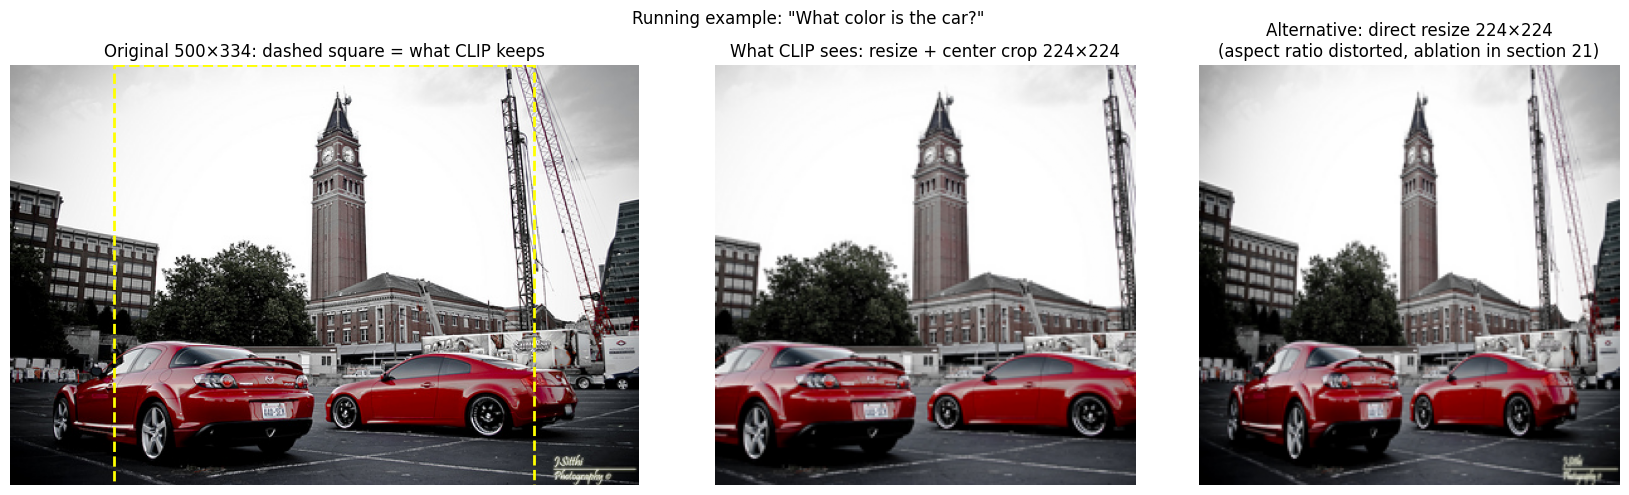

In [20]:
# 5.2 — Original image vs what CLIP sees
# Undo steps 4 and 3 (x·σ + μ), then C×H×W → H×W×C for matplotlib
seen_by_clip = (pixel_values[0] * std + mean).clamp(0, 1).permute(1, 2, 0)
show("seen by CLIP (H×W×C)", seen_by_clip)

# Crop window in ORIGINAL coordinates: the resize multiplied every coordinate by s
s = S / min(w, h)
crop_x, crop_y, crop_side = left / s, top / s, S / s
kept = crop_side ** 2 / (w * h)
print(f"Resize scale s = {s:.4f} → crop window in the original: x = {crop_x:.0f}, y = {crop_y:.0f}, side = {crop_side:.0f} px")
print(f"Share of the original area that CLIP sees: {kept:.1%}  (cut off: {1 - kept:.1%})")

# Alternative without crop (ablation, section 21): whole image, distorted aspect ratio
squashed = example_image.resize((S, S), Image.Resampling.BICUBIC)
print(f"Direct resize instead: width × {S / w:.3f}, height × {S / h:.3f}  (aspect ratio not kept)")

fig, axes = plt.subplots(1, 3, figsize=(17, 5), gridspec_kw={"width_ratios": [w / h, 1, 1]})
axes[0].imshow(example_image)
axes[0].add_patch(plt.Rectangle((crop_x, crop_y), crop_side, crop_side, fill=False, ec="yellow", lw=2, ls="--"))
axes[0].set_title(f"Original {w}×{h}: dashed square = what CLIP keeps")
axes[1].imshow(seen_by_clip.numpy())
axes[1].set_title(f"What CLIP sees: resize + center crop {S}×{S}")
axes[2].imshow(squashed)
axes[2].set_title(f"Alternative: direct resize {S}×{S}\n(aspect ratio distorted, ablation in section 21)")
for ax in axes:
    ax.axis("off")
fig.suptitle(f'Running example: "{EXAMPLE["question"]}"')
fig.tight_layout()
fig.savefig(cfg.path("fig", "5_2_crop.png"), dpi=120, bbox_inches="tight")
plt.show()

### 5.3 The patch grid: one patch = one visual token

**Goal**: see the 196 pieces the ViT cuts the image into, and how they are numbered.

$224 / 16 = 14$, so the image is a **14×14 grid of 196 patches**, each made of $16 \times 16 \times 3 = 768$ values. Each patch becomes **one token** of the ViT (section 6), and later one candidate for the selector.

**Numbering (row-major).** Patch $(r, c)$ has index $p = 14\,r + c$: left to right, then top to bottom, like reading a page. This is the order of the ViT tokens after the CLS (position $p + 1$ in the 197-token sequence). It matters in section 11: sorting the selected indices puts the tokens back in this reading order.

**Cutting with `unfold`.** `x.unfold(dim, size, step)` slides a window of length `size` along `dim` with stride `step`. With `size = step = 16`, the windows are non-overlapping blocks. Two unfolds (height, then width):

$$
(3, 224, 224) \xrightarrow{\text{unfold dim 1}} (3, 14, 224, 16) \xrightarrow{\text{unfold dim 2}} (3, 14, 14, 16, 16) \xrightarrow{\text{permute, reshape}} (196, 768)
$$

The `permute` moves the two grid dimensions first, so that row $p$ of the result is patch $p$. Each patch is flattened in (C, 16, 16) order: the same layout as the weight `(768, 3, 16, 16)` of the ViT's patch-embedding `Conv2d`. A convolution with kernel 16 and stride 16 is exactly a linear layer applied to each flattened patch (section 2.2), which we can check on the real CLIP weights in section 6.

⚠️ $768 = 16 \cdot 16 \cdot 3$ equals `cfg.d_vision` = 768 by **coincidence**: it is the hidden size of ViT-B. For ViT-L/14, a patch has $14 \cdot 14 \cdot 3 = 588$ values and the hidden size is 1024.

The figure numbers every patch on the image and zooms on one of them (a patch on the left car, chosen for display only).

unfold → (C, G, G, P, P)     (3, 14, 14, 16, 16) float32   cpu  min=-1.792 max=+2.146 mean=+0.547 std=1.407
patches (196×768)            (196, 768)         float32   cpu  min=-1.792 max=+2.146 mean=+0.547 std=1.407

14×14 = 196 patches of 16×16×3 = 768 values each
Zoomed patch: row 11, col 3 → index p = 14·11 + 3 = 157  (position 158 in the 197-token ViT sequence, CLS at position 0)


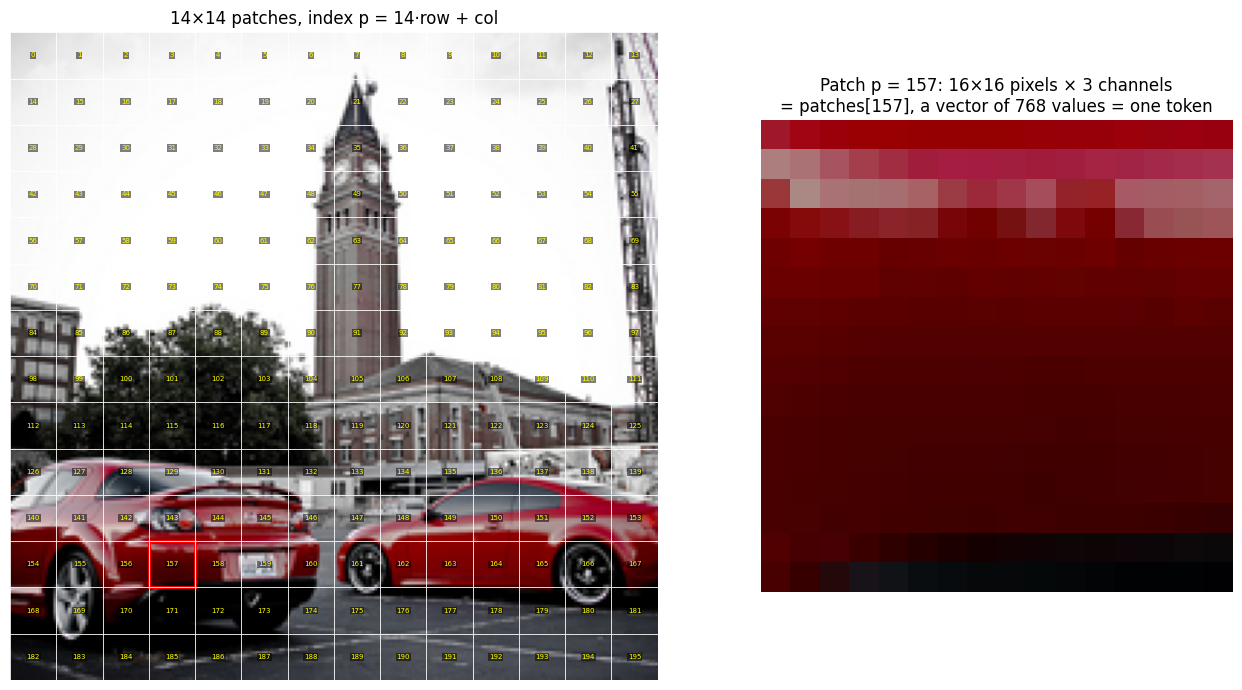

In [21]:
# 5.3 — The 14×14 patch grid: one 16×16 patch = one visual token
P, G = cfg.patch_size, cfg.grid_size
ZOOM_PATCH = (11, 3)    # display only: (row, col) of a patch on the left car of the running example

# (3, 224, 224) → unfold height → (3, 14, 224, 16) → unfold width → (3, 14, 14, 16, 16)
patch_grid = pixel_values[0].unfold(1, P, P).unfold(2, P, P)
show("unfold → (C, G, G, P, P)", patch_grid)
# Grid dims first → (14, 14, 3, 16, 16), then one row per patch: row p = patch (p // G, p % G)
patches = patch_grid.permute(1, 2, 0, 3, 4).reshape(G * G, 3 * P * P)
show("patches (196×768)", patches)
assert patches.shape == (cfg.n_patches, 3 * P * P)

zr, zc = ZOOM_PATCH
zoom_p = G * zr + zc
print(f"\n{G}×{G} = {G * G} patches of {P}×{P}×3 = {3 * P * P} values each")
print(f"Zoomed patch: row {zr}, col {zc} → index p = {G}·{zr} + {zc} = {zoom_p}  "
      f"(position {zoom_p + 1} in the 197-token ViT sequence, CLS at position 0)")

fig, axes = plt.subplots(1, 2, figsize=(14, 7), gridspec_kw={"width_ratios": [2, 1]})
ax = axes[0]
ax.imshow(seen_by_clip.numpy())
for k in range(G + 1):                                   # patch borders (pixel centers are at integers)
    ax.axhline(k * P - 0.5, color="white", lw=0.6)
    ax.axvline(k * P - 0.5, color="white", lw=0.6)
for idx in range(G * G):
    r, c = divmod(idx, G)
    ax.text(c * P + P / 2 - 0.5, r * P + P / 2 - 0.5, str(idx), ha="center", va="center", fontsize=5, color="yellow",
            bbox=dict(facecolor="black", alpha=0.5, pad=0.5, lw=0))
ax.add_patch(plt.Rectangle((zc * P - 0.5, zr * P - 0.5), P, P, fill=False, ec="red", lw=2))
ax.set_title(f"{G}×{G} patches, index p = {G}·row + col")
ax.axis("off")

# The zoomed patch, rebuilt from ITS ROW of `patches` (denormalized for display)
patch_img = (patches[zoom_p].view(3, P, P) * std + mean).clamp(0, 1).permute(1, 2, 0)
axes[1].imshow(patch_img.numpy(), interpolation="nearest")
axes[1].set_title(f"Patch p = {zoom_p}: {P}×{P} pixels × 3 channels\n= patches[{zoom_p}], a vector of {3 * P * P} values = one token")
axes[1].axis("off")
fig.tight_layout()
fig.savefig(cfg.path("fig", "5_3_patch_grid.png"), dpi=120, bbox_inches="tight")
plt.show()

### 5.4 Section 5 checks

1. **Running-example tensor**: shape 1×3×224×224, `float32`, no NaN / inf, and the manual pipeline gives the same tensor as the processor.
2. **Value range**: before normalization, $x \in [0, 1]$; after, each channel must lie in $[-\mu_c/\sigma_c,\ (1 - \mu_c)/\sigma_c]$. This bound is exact, not a tolerance.
3. **Denormalization** (5.2) gives back the cropped image, and the crop window lies inside the original image.
4. **Patches** (5.3): shape 196×768, patch $p$ is the image block at row $p // 14$, column $p \bmod 14$, and putting the 196 patches back in place gives the image again, **exactly**.
5. **Normalization over many images** (PLAN: "mean close to 0"): per-channel mean and std over the subset images (at most `N_STATS_IMAGES`, drawn with `cfg.seed`).

**Why these tolerances for check 5**: $|\text{mean}| < 0.25$ and $0.75 < \text{std} < 1.25$. They are set to catch the two real bugs, not to measure how well CLIP's statistics fit COCO:

* **normalization forgotten**: values stay in [0, 1], so mean ≈ 0.45 and std ≈ 0.27 → fails;
* **normalization applied twice**: dividing by $\sigma \approx 0.27$ again multiplies the spread by ~3.7 → std ≈ 3.7 → fails.

COCO is not CLIP's training set, so we do not expect exactly 0 and 1.

In [22]:
# 5.4 — Section 5 checks
N_STATS_IMAGES = 500    # check setting, not a hyperparameter: max number of subset images for check 5

checks = {}

# ---- 1. Running-example tensor
checks["pixel_values: shape 1×3×224×224, float32"] = (
    pixel_values.shape == (1, 3, cfg.image_size, cfg.image_size) and pixel_values.dtype == torch.float32)
checks["pixel_values: no NaN / inf"] = torch.isfinite(pixel_values).all().item()
checks["manual pipeline = processor"] = torch.allclose(x, pixel_values[0], atol=1e-5)

# ---- 2. Exact value range: x ∈ [0, 1] before step 4 → x_c ∈ [−μ_c/σ_c, (1 − μ_c)/σ_c] after
lo, hi = (0 - mean) / std, (1 - mean) / std                       # (3, 1, 1), broadcast over H and W
checks["values within [−μ/σ, (1 − μ)/σ] per channel"] = (
    (pixel_values[0] >= lo - 1e-5).all() and (pixel_values[0] <= hi + 1e-5).all()).item()

# ---- 3. Denormalization and crop window (5.2)
cropped_01 = torch.from_numpy(np.array(cropped)).float() / 255    # H×W×C in [0, 1]
checks["denormalized tensor = cropped image (error < 1e-3 on the 0–255 scale)"] = (
    (seen_by_clip - cropped_01).abs().max().item() * 255 < 1e-3)
checks["crop window inside the original image"] = (
    crop_x >= 0 and crop_y >= 0 and crop_x + crop_side <= w + 1e-6 and crop_y + crop_side <= h + 1e-6)

# ---- 4. Patches (5.3)
checks["patches: shape 196×768"] = patches.shape == (cfg.n_patches, 3 * P * P)
checks["patch p = image block (p // 14, p % 14), for every p"] = all(
    torch.equal(patches[p], pixel_values[0, :, (p // G) * P:(p // G + 1) * P, (p % G) * P:(p % G + 1) * P].reshape(-1))
    for p in range(cfg.n_patches))
# Inverse of 5.3: (196, 768) → (14, 14, 3, 16, 16) → (3, 14, 16, 14, 16) → (3, 224, 224)
refolded = patches.view(G, G, 3, P, P).permute(2, 0, 3, 1, 4).reshape(3, G * P, G * P)
checks["patches → image round trip is exact"] = torch.equal(refolded, pixel_values[0])

# ---- 5. Normalization over many images: per-channel mean ≈ 0 and std ≈ 1
image_keys = data_df[["coco_split", "image_id"]].drop_duplicates()
image_keys = image_keys.sample(n=min(N_STATS_IMAGES, len(image_keys)), random_state=cfg.seed)
moments = []
for coco_split, image_id in tqdm(image_keys.itertuples(index=False, name=None), total=len(image_keys),
                                 desc="normalization stats"):
    with Image.open(coco_image_path(coco_split, image_id)) as im:
        xi = image_processor(images=im.convert("RGB"), return_tensors="pt")["pixel_values"][0]
    moments.append(torch.stack([xi.mean(dim=(1, 2)), (xi ** 2).mean(dim=(1, 2))]))   # (2, 3): E[x], E[x²] per channel
# Every image has 224×224 pixels, so averaging the per-image moments gives the exact global moments
ex, ex2 = torch.stack(moments).mean(dim=0)
ch_mean, ch_std = ex, (ex2 - ex ** 2).sqrt()
print(f"Over {len(image_keys)} subset images: mean (R, G, B) = {ch_mean.numpy().round(3)}, "
      f"std (R, G, B) = {ch_std.numpy().round(3)}")
checks["per-channel mean ≈ 0  (|mean| < 0.25)"] = (ch_mean.abs() < 0.25).all().item()
checks["per-channel std ≈ 1  (0.75 < std < 1.25)"] = ((ch_std > 0.75) & (ch_std < 1.25)).all().item()

# ---- Summary
print()
for name, ok in checks.items():
    print(f"{'✅' if ok else '❌'} {name}")
assert all(checks.values()), "A section 5 check failed: do not move on to section 6."
print("\nSection 5 validated → we can move on to section 6.")

normalization stats:   0%|          | 0/60 [00:00<?, ?it/s]

Over 60 subset images: mean (R, G, B) = [-0.065 -0.066 -0.05 ], std (R, G, B) = [0.984 0.987 0.994]

✅ pixel_values: shape 1×3×224×224, float32
✅ pixel_values: no NaN / inf
✅ manual pipeline = processor
✅ values within [−μ/σ, (1 − μ)/σ] per channel
✅ denormalized tensor = cropped image (error < 1e-3 on the 0–255 scale)
✅ crop window inside the original image
✅ patches: shape 196×768
✅ patch p = image block (p // 14, p % 14), for every p
✅ patches → image round trip is exact
✅ per-channel mean ≈ 0  (|mean| < 0.25)
✅ per-channel std ≈ 1  (0.75 < std < 1.25)

Section 5 validated → we can move on to section 6.


---
# Part III: the encoders

## Section 6. The visual encoder (CLIP ViT-B/16)

**Goal**: turn every image into the visual tokens the selector will choose from, and cache them on disk. CLIP is frozen, so its outputs never change during training: we compute them **once**, instead of running the ViT again at every epoch.

| Subsection | Role |
|---|---|
| 6.1 | Load the vision tower of CLIP, freeze it, switch it to eval mode |
| 6.2 | Inside the embeddings: patch embedding = a linear layer, CLS token, positional embedding |
| 6.3 | Forward with all the hidden states (13 tensors) and attentions; penultimate layer, CLS / 196 patches, last-layer CLS attention |
| 6.4 | Extract the features of the whole subset and store them on disk in fp16 |
| 6.5 | Section checks |

What we cache, per image:

| Tensor | Shape | Used in |
|---|---|---|
| `patches` = V | 196×768 | selector, projector, training (sections 9 – 18) |
| `cls` | 768 | the "CLS always included" ablation (section 21) |
| `cls_attn` | 196 | CLS attention map (section 8), CLS-attention baseline (section 11) |

### 6.1 Loading the frozen vision encoder

**Goal**: load only the **vision tower** of `cfg.clip_name`, freeze it and put it in eval mode.

* **`CLIPVisionModel`, not `CLIPModel`.** The checkpoint holds the image encoder, the text encoder and the two projections into the shared image-text space. Here we only need the image encoder (the text encoder comes in section 7). Loading `CLIPVisionModel` from the full checkpoint simply skips the other weights.
* **`attn_implementation="eager"`.** By default, `transformers` uses PyTorch's fused attention (`sdpa`). It is faster, but it never materializes the 197×197 attention matrix, so `output_attentions=True` silently returns `None` (with only a log warning). We need that matrix for the CLS attention (6.3), so we ask for the plain implementation, which computes $\mathrm{softmax}(QK^\top/\sqrt{d_k})\,V$ step by step.
* **Freezing means two different things.** `requires_grad_(False)`: no gradient is computed for the weights (and no memory is spent on it). `eval()`: layers whose *behavior* differs between training and inference (dropout, for instance) switch to inference mode. Neither implies the other, so we do both.
* **Precision.** The weights are loaded directly in `DTYPE` (fp16 on a T4, fp32 on CPU, section 3.4).

The cell checks that the model's configuration matches `cfg` (hidden size, patch size, image size): every shape in the notebook depends on these values.

In [23]:
# 6.1 — Load the CLIP vision tower, frozen, in eval mode
from transformers import CLIPVisionModel

# "eager": the default attention (sdpa) does not return the attention weights needed in 6.3
clip_vision = CLIPVisionModel.from_pretrained(cfg.clip_name, dtype=DTYPE, attn_implementation="eager")
clip_vision = clip_vision.to(DEVICE).eval()
clip_vision.requires_grad_(False)

vcfg = clip_vision.config
print(f"hidden size {vcfg.hidden_size}, patch {vcfg.patch_size}, image {vcfg.image_size}, "
      f"{vcfg.num_hidden_layers} layers, {vcfg.num_attention_heads} heads of dim {vcfg.hidden_size // vcfg.num_attention_heads}")
print(f"attention: {vcfg._attn_implementation}, dtype: {clip_vision.dtype}, device: {clip_vision.device}")
total, trainable = count_params(clip_vision)
print(f"parameters: {total / 1e6:.1f}M, of which trainable: {trainable}")

assert (vcfg.hidden_size, vcfg.patch_size, vcfg.image_size) == (cfg.d_vision, cfg.patch_size, cfg.image_size), \
    "the CLIP config does not match cfg"
assert trainable == 0 and not clip_vision.training
gpu_mem("after loading CLIP")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

hidden size 768, patch 16, image 224, 12 layers, 12 heads of dim 64
attention: eager, dtype: torch.float32, device: cpu
parameters: 85.8M, of which trainable: 0


### 6.2 Inside the embeddings: patches, CLS and positions

**Goal**: rebuild by hand, from the patches of 5.3 and CLIP's real weights, the input of the first Transformer block (section 2.2):

$$
z_0 = \mathrm{LN}_{pre}\big([\,x_{cls};\ x_1 E;\ \dots;\ x_{196} E\,] + E_{pos}\big) \in \mathbb{R}^{197 \times 768}
$$

* **Patch embedding = a linear layer.** CLIP implements $E$ as `Conv2d(3, 768, kernel_size=16, stride=16, bias=False)`, with a weight of shape (768, 3, 16, 16). Since kernel = stride = 16, each output position sees exactly one patch, with no overlap. The convolution is therefore the product of each flattened patch (768 values in (C, 16, 16) order, section 5.3) with the weight reshaped to (768, 768). We check this on the real weights.
* **CLS token.** A single learned vector `class_embedding` (768), the same for every image, placed at position 0. At the input it carries **no** information about the image: it gathers it layer after layer through attention. CLIP is trained on the CLS of the **last** layer only: after `post_layernorm` and a linear projection, it is the image embedding of the contrastive loss.
* **Positional embedding.** A learned table $E_{pos}$ of 197×768 (one row per position, CLS included), **added** to the tokens. Without it, attention is permutation-invariant: shuffling the patches would only shuffle the outputs.
* **`pre_layrnorm`**: a specificity of the OpenAI CLIP ViT, a LayerNorm applied **before** the first block. The 13 hidden states of 6.3 start after it.

All the computation is done by hand in fp32 on CPU, then compared to CLIP's own modules with `rel_err` (relative error $\lVert a - b \rVert / \lVert b \rVert$, independent of the scale of the values). The tolerance `REL_TOL` covers fp16 rounding (relative precision $2^{-11} \approx 5 \cdot 10^{-4}$ per value, a bit more after several layers). A real bug (missing CLS, positions not added, patches in the wrong order) gives an error of order 1.

**Concept: what the positions learned.** Nothing tells the model that patch 14 is just below patch 0: the table is learned freely. The figure shows, for a few patches, the cosine similarity of their position vector with the 196 others, as a 14×14 map. If the model learned the 2D layout, each map is bright around its own patch. The cell also prints the average similarity between neighbouring patches and between distant patches.

patch_embedding.weight       (768, 3, 16, 16)   float32   cpu  min=-0.148 max=+0.144 mean=+0.000 std=0.019
class_embedding              (768,)             float32   cpu  min=-1.554 max=+1.003 mean=+0.003 std=0.234
position_embedding.weight    (197, 768)         float32   cpu  min=-0.220 max=+0.237 mean=-0.007 std=0.028

conv patch embedding         (196, 768)         float32   cpu  min=-6.008 max=+4.883 mean=+0.010 std=0.519
linear patch embedding       (196, 768)         float32   cpu  min=-6.008 max=+4.883 mean=+0.010 std=0.519
z0 by hand (197×768)         (197, 768)         float32   cpu  min=-5.823 max=+2.260 mean=+0.007 std=0.169
z0 CLIP                      (197, 768)         float32   cpu  min=-5.823 max=+2.260 mean=+0.007 std=0.169
max |conv − linear| = 5.89e-06
z0 by hand vs CLIP: relative error = 1.76e-06

Mean cosine similarity of position vectors: neighbours (distance 1) = 0.663, distant patches (distance ≥ 7) = 0.330


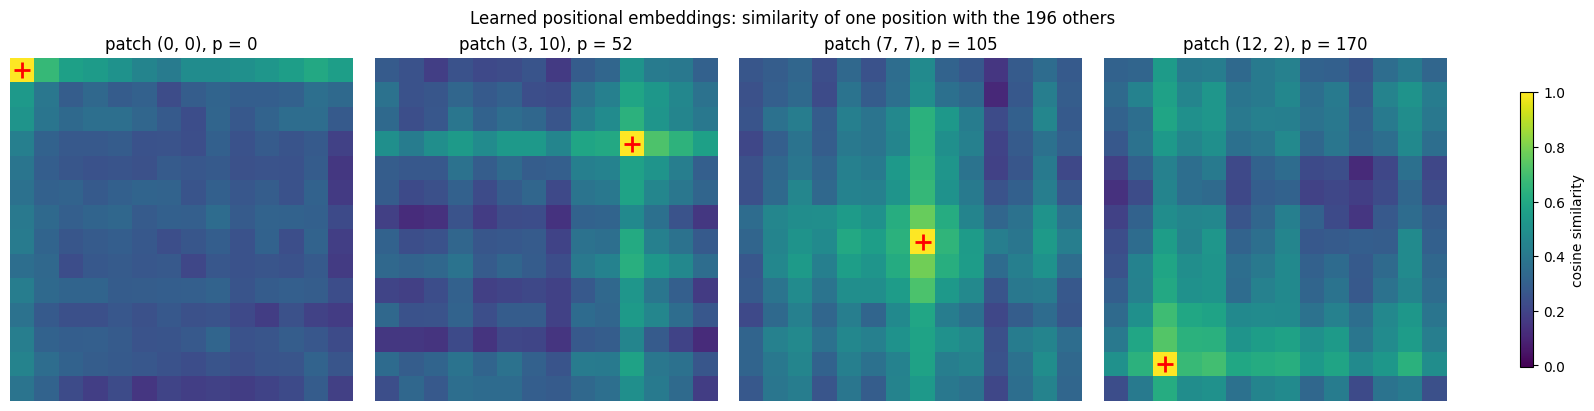

In [24]:
# 6.2 — The embeddings by hand: patch embedding, CLS, positional embedding, pre-LayerNorm
REL_TOL = 1e-2   # check setting: fp16 rounding gives ~1e-3, a real bug gives ~1


def rel_err(a: torch.Tensor, b: torch.Tensor) -> float:
    # ‖a − b‖ / ‖b‖ in fp32 on CPU: a scale-free distance between two tensors
    a, b = a.detach().float().cpu(), b.detach().float().cpu()
    return ((a - b).norm() / b.norm()).item()


vm = clip_vision.vision_model
# fp32 CPU copies of CLIP's weights: the hand computation is done in full precision
W_patch = vm.embeddings.patch_embedding.weight.float().cpu()        # (768, 3, 16, 16)
cls_vec = vm.embeddings.class_embedding.float().cpu()               # (768,)
E_pos = vm.embeddings.position_embedding.weight.float().cpu()       # (197, 768), row 0 = CLS position
show("patch_embedding.weight", W_patch)
show("class_embedding", cls_vec)
show("position_embedding.weight", E_pos)

# 1. Patch embedding the way CLIP computes it: a convolution, kernel = stride = 16
#    (1, 3, 224, 224) → (1, 768, 14, 14) → flatten the grid (row-major, as in 5.3) → (196, 768)
conv_out = F.conv2d(pixel_values, W_patch, stride=cfg.patch_size).flatten(2).transpose(1, 2)[0]
# 2. The same thing as a linear layer on the flattened patches of 5.3: (196, 768) @ (768, 768)ᵀ
linear_out = patches @ W_patch.reshape(cfg.d_vision, -1).T
# 3. CLS in front → (197, 768), positions added, then the pre-LayerNorm
z0 = torch.cat([cls_vec[None], linear_out]) + E_pos
z0 = F.layer_norm(z0, (cfg.d_vision,), vm.pre_layrnorm.weight.float().cpu(), vm.pre_layrnorm.bias.float().cpu(),
                  vm.pre_layrnorm.eps)
# Reference: CLIP's own modules (in DTYPE, on DEVICE)
with torch.no_grad():
    z0_clip = vm.pre_layrnorm(vm.embeddings(pixel_values.to(DEVICE, DTYPE)))[0]

print()
show("conv patch embedding", conv_out)
show("linear patch embedding", linear_out)
show("z0 by hand (197×768)", z0)
show("z0 CLIP", z0_clip)
print(f"max |conv − linear| = {(conv_out - linear_out).abs().max():.2e}")
print(f"z0 by hand vs CLIP: relative error = {rel_err(z0, z0_clip):.2e}")
assert torch.allclose(conv_out, linear_out, atol=1e-4), "the patch embedding is not a linear layer on the patches"
assert rel_err(z0, z0_clip) < REL_TOL, "z0 by hand ≠ CLIP embeddings"

# ---- What the positional embeddings learned
SHOW_POSITIONS = [(0, 0), (3, 10), (7, 7), (12, 2)]   # display only: (row, col) of a few patches
pos = F.normalize(E_pos[1:], dim=-1)                   # (196, 768), CLS position excluded
pos_sim = pos @ pos.T                                  # (196, 196) cosine similarities
rows, cols = torch.arange(cfg.n_patches) // G, torch.arange(cfg.n_patches) % G
grid_dist = (rows[:, None] - rows[None]).abs() + (cols[:, None] - cols[None]).abs()   # (196, 196) Manhattan distance
print(f"\nMean cosine similarity of position vectors: neighbours (distance 1) = {pos_sim[grid_dist == 1].mean():.3f}, "
      f"distant patches (distance ≥ {G // 2}) = {pos_sim[grid_dist >= G // 2].mean():.3f}")

fig, axes = plt.subplots(1, len(SHOW_POSITIONS), figsize=(4 * len(SHOW_POSITIONS), 4), layout="constrained")
for ax, (r, c) in zip(axes, SHOW_POSITIONS):
    im = ax.imshow(pos_sim[G * r + c].view(G, G), cmap="viridis", vmin=pos_sim.min(), vmax=1)
    ax.plot(c, r, "r+", ms=12, mew=2)
    ax.set_title(f"patch ({r}, {c}), p = {G * r + c}")
    ax.axis("off")
fig.colorbar(im, ax=axes, shrink=0.8, label="cosine similarity")
fig.suptitle("Learned positional embeddings: similarity of one position with the 196 others")
fig.savefig(cfg.path("fig", "6_2_positional_embeddings.png"), dpi=120, bbox_inches="tight")
plt.show()

### 6.3 The forward pass: 13 hidden states, penultimate layer, CLS attention

**Goal**: run the ViT on the running example, keep every intermediate output, and extract the three tensors we cache.

With `output_hidden_states=True`, the model returns **13** tensors of shape (B, 197, 768): $z_0$ (the input of the first block, rebuilt in 6.2), then the output of each of the 12 blocks. With `output_attentions=True`, it also returns the **12** attention matrices, of shape (B, heads, 197, 197), after the softmax over the keys (last axis).

**What we keep:**

* `hidden_states[cfg.vision_feature_layer]` = `hidden_states[-2]`, the output of block 11. Position 0 is the CLS, positions 1 to 196 are the patches in the row-major order of 5.3 → `cls` (768) and `patches` V (196×768).
* `attentions[-1][:, :, 0, 1:]`: in the **last** block, the attention row of the CLS (query 0) over the 196 patches (keys 1 to 196), averaged over the 12 heads → `cls_attn` (196).

**Concept: why the penultimate layer.** CLIP's contrastive loss only uses the CLS output of the last block. Follow the gradient backwards:

* in the last block, the 196 patch **outputs** are not used by anything: no gradient ever reaches them. They are computed with the same weights as the CLS, but nothing in training constrains what they contain;
* the output of block 11 is the input of block 12, from which the CLS computes its keys and values: it is directly shaped by the loss.

The penultimate layer is therefore the last one whose patch tokens are trained to be useful. LLaVA makes the same choice (`vision_feature_layer = -2`). The layer used is an ablation of section 21.

The cell prints, for each of the 13 hidden states, the mean and maximum norm of the patch tokens and the mean cosine similarity between two different patches. If the patch outputs of the last block are unconstrained, nothing prevents them from becoming similar to one another, i.e. less specific to their location: compare the last two rows. This is one image, a description rather than a proof. Section 8 analyses the tokens further (including the few tokens with a very large norm, if there are some).

**Why the attention of the last layer.** It is exactly how the CLS, the vector CLIP is trained on, weighs the penultimate tokens we keep: the query is the CLS of block 12, the keys are computed from the 196 tokens of `hidden_states[-2]`. It is a score for **our** tokens that ignores the question: the "CLS attention" baseline of section 11. Each softmax row sums to 1 over the 197 keys; since we drop the CLS → CLS entry, our 196 values sum to slightly less than 1 (the cell prints how much).

**Pitfall: `pooler_output` is not `hidden_states[-1][:, 0]`.** `pooler_output` is the last CLS **after** `post_layernorm`. We use neither of them.

`encode_images` wraps these few lines because they are reused: for the extraction (6.4), the live check (6.5), and later the forward pass from pixels (sections 16 and 20).

In [25]:
# 6.3 — Forward with all hidden states and attentions; penultimate layer, CLS / patches, CLS attention

@torch.no_grad()
def encode_images(pixel_values: torch.Tensor) -> dict:
    # (B, 3, 224, 224) → patches (B, 196, 768) and cls (B, 768) of layer cfg.vision_feature_layer,
    #                   cls_attn (B, 196): last-layer attention of the CLS over the patches, mean over heads
    out = clip_vision(pixel_values=pixel_values.to(DEVICE, DTYPE), output_hidden_states=True, output_attentions=True)
    h = out.hidden_states[cfg.vision_feature_layer]           # (B, 197, 768)
    attn = out.attentions[-1]                                 # (B, heads, 197 queries, 197 keys)
    return {
        "patches": h[:, 1:],                                  # (B, 196, 768): positions 1..196, row-major
        "cls": h[:, 0],                                       # (B, 768)
        "cls_attn": attn[:, :, 0, 1:].mean(dim=1),            # query 0 (CLS), keys 1..196 (patches) → (B, 196)
    }


# ---- 1. Everything the ViT computes, on the running example
with torch.no_grad():
    vit_out = clip_vision(pixel_values=pixel_values.to(DEVICE, DTYPE), output_hidden_states=True, output_attentions=True)
print(f"{len(vit_out.hidden_states)} hidden states, {len(vit_out.attentions)} attention matrices")
show("hidden_states[0] = z0", vit_out.hidden_states[0])
show(f"hidden_states[{cfg.vision_feature_layer}]", vit_out.hidden_states[cfg.vision_feature_layer])
show("hidden_states[-1]", vit_out.hidden_states[-1])
show("attentions[-1]", vit_out.attentions[-1])
print(f"hidden_states[0] vs z0 by hand (6.2): relative error = {rel_err(vit_out.hidden_states[0][0], z0):.2e}")
print(f"pooler_output vs hidden_states[-1][:, 0]: relative error = "
      f"{rel_err(vit_out.pooler_output, vit_out.hidden_states[-1][:, 0]):.2e}  (not the same tensor: post_layernorm)")
assert len(vit_out.hidden_states) == vcfg.num_hidden_layers + 1 and len(vit_out.attentions) == vcfg.num_hidden_layers
assert rel_err(vit_out.hidden_states[0][0], z0) < REL_TOL

# ---- 2. How the patch tokens change with depth (one image: a description, not a proof)
n_layers = len(vit_out.hidden_states)
kept_layer = cfg.vision_feature_layer % n_layers                  # -2 → 11
print(f"\n{'layer':>5}  {'patch norm: mean':>16}  {'max':>7}  {'mean cos(patch i, patch j), i ≠ j':>34}")
for layer, h in enumerate(vit_out.hidden_states):
    p = h[0, 1:].float()                                          # (196, 768)
    pn = F.normalize(p, dim=-1)
    # Mean over the 196·195 pairs i ≠ j: sum of the similarity matrix minus its diagonal of ones
    mean_cos = ((pn @ pn.T).sum() - cfg.n_patches) / (cfg.n_patches * (cfg.n_patches - 1))
    norms = p.norm(dim=-1)
    tag = "   ← kept" if layer == kept_layer else ""
    print(f"{layer:>5}  {norms.mean():>16.2f}  {norms.max():>7.2f}  {mean_cos:>34.3f}{tag}")

# ---- 3. The three tensors we cache, for the running example
example_feats = encode_images(pixel_values)
print()
show("CLIP ViT output (197×768)", vit_out.hidden_states[cfg.vision_feature_layer][0])
show("V = patches (196×768)", example_feats["patches"][0])
show("cls (768)", example_feats["cls"][0])
show("cls_attn (196)", example_feats["cls_attn"][0])
assert example_feats["patches"].shape == (1, cfg.n_patches, cfg.d_vision)
assert example_feats["cls"].shape == (1, cfg.d_vision) and example_feats["cls_attn"].shape == (1, cfg.n_patches)

cls_self = vit_out.attentions[-1][0, :, 0, 0].float().mean()
print(f"\ncls_attn sums to {example_feats['cls_attn'].float().sum():.3f} over the 196 patches "
      f"(CLS → CLS, mean over heads: {cls_self:.3f})")
top = example_feats["cls_attn"][0].float().topk(5)
print("Patches the CLS attends to most, p (row, col): weight →",
      ", ".join(f"{p} ({p // G}, {p % G}): {a:.3f}" for a, p in zip(top.values.tolist(), top.indices.tolist())))

13 hidden states, 12 attention matrices
hidden_states[0] = z0        (1, 197, 768)      float32   cpu  min=-5.823 max=+2.260 mean=+0.007 std=0.169
hidden_states[-2]            (1, 197, 768)      float32   cpu  min=-17.441 max=+89.325 mean=-0.012 std=0.710
hidden_states[-1]            (1, 197, 768)      float32   cpu  min=-17.969 max=+80.953 mean=-0.022 std=0.788
attentions[-1]               (1, 12, 197, 197)  float32   cpu  min=+0.000 max=+0.325 mean=+0.005 std=0.006
hidden_states[0] vs z0 by hand (6.2): relative error = 1.76e-06
pooler_output vs hidden_states[-1][:, 0]: relative error = 2.88e+00  (not the same tensor: post_layernorm)

layer  patch norm: mean      max   mean cos(patch i, patch j), i ≠ j
    0              4.65     6.93                               0.239
    1              3.45     4.37                               0.294
    2              4.10     4.75                               0.281
    3              3.60     4.53                               0.160
    4      

### 6.4 Extracting and caching the features of the subset

**Goal**: run `encode_images` once on every image of the subset, and store the result on persistent storage.

**One row per image, not per question.** An image has ~5 questions (4.4) and its visual tokens do not depend on the question. Each image is stored once, with its `image_id`; later sections find the features of a question through its `image_id`.

**fp16 storage.** For one image, V takes $196 \times 768 \times 2$ bytes $= 301{,}056$ bytes ≈ 301 KB (1 KB = 1,000 bytes), half of what fp32 would take. `cls` and `cls_attn` add $(768 + 196) \times 2$ bytes. fp16 keeps about 3 significant digits. That is enough: downstream, the models run in fp16 or bf16 (section 3.4), which are not more precise. The cell prints the size this gives in full mode.

**One file per split**, `clip_layer-2_<split>.pt`, in `cfg.cache_dir` (which depends on the run, so DEBUG and full mode never mix). The layer is in the file name: the layer ablation (section 21) will write new files instead of overwriting these ones.

| Key | Shape | dtype |
|---|---|---|
| `image_ids` | N | int64 |
| `patches` | N×196×768 | float16 |
| `cls` | N×768 | float16 |
| `cls_attn` | N×196 | float16 |

Rows are in increasing `image_id` order, so the file does not depend on the row order of `data_df`.

**Memory.** The output tensors are allocated once (`torch.empty`), then filled batch by batch. Accumulating the batches in a list and calling `torch.cat` at the end would hold two copies at the peak: about 6 GB instead of 3 for the full-mode train split.

**Resume.** One `load_or_compute` per split: after a disconnection, the splits already saved are reloaded, and only the interrupted one is recomputed.

`EXTRACT_BATCH_SIZE` is a runtime setting (speed and memory), not a hyperparameter: it changes the features only through floating-point rounding, which 6.5 checks.

In [26]:
# 6.4 — Extract the CLIP features of the whole subset, cache them in fp16
EXTRACT_BATCH_SIZE = 64          # runtime setting, not a hyperparameter: speed / memory only (checked in 6.5)
SPLITS = list(SPLIT_SOURCE)      # ["train", "dev", "test"]
CACHED_KEYS = ("patches", "cls", "cls_attn")


def clip_cache_path(split: str) -> Path:
    return cfg.path("cache", f"clip_layer{cfg.vision_feature_layer}_{split}.pt")


def extract_split(split: str) -> dict:
    # Encodes each image of `split` once. Rows in increasing image_id order.
    keys = (data_df.loc[data_df["split"] == split, ["coco_split", "image_id"]]
            .drop_duplicates().sort_values("image_id"))
    keys = list(keys.itertuples(index=False, name=None))
    n = len(keys)
    # Allocated once, then filled batch by batch: no second copy at the peak
    feats = {
        "image_ids": torch.tensor([image_id for _, image_id in keys]),
        "patches": torch.empty(n, cfg.n_patches, cfg.d_vision, dtype=torch.float16),
        "cls": torch.empty(n, cfg.d_vision, dtype=torch.float16),
        "cls_attn": torch.empty(n, cfg.n_patches, dtype=torch.float16),
    }
    for start in tqdm(range(0, n, EXTRACT_BATCH_SIZE), desc=f"CLIP {split}"):
        batch = keys[start:start + EXTRACT_BATCH_SIZE]
        images = []
        for coco_split, image_id in batch:
            with Image.open(coco_image_path(coco_split, image_id)) as im:
                images.append(im.convert("RGB"))
        out = encode_images(image_processor(images=images, return_tensors="pt")["pixel_values"])
        for k in CACHED_KEYS:
            feats[k][start:start + len(batch)] = out[k].cpu()     # copy into the fp16 tensor (cast if needed)
    return feats


clip_feats = {}
for split in SPLITS:
    clip_feats[split] = load_or_compute(clip_cache_path(split), lambda: extract_split(split))

# ---- What is on disk
print()
for split, f in clip_feats.items():
    size = clip_cache_path(split).stat().st_size
    print(f"{split:<6} {len(f['image_ids']):>6} images   {size / 1e6:8.1f} MB   {size / len(f['image_ids']) / 1e3:6.1f} KB / image")
for k in ("image_ids", *CACHED_KEYS):
    show(f"train {k}", clip_feats["train"][k])

# Expected size in full mode, from the config (not a measurement)
bytes_per_image = (cfg.n_patches * cfg.d_vision + cfg.d_vision + cfg.n_patches) * 2
full = Config(debug=False)
n_full = full.n_train_images + full.n_dev_images + full.n_test_images
print(f"\nExpected in full mode: {n_full} images × {bytes_per_image / 1e3:.1f} KB = {n_full * bytes_per_image / 1e9:.2f} GB "
      f"(train split alone: {full.n_train_images * bytes_per_image / 1e9:.2f} GB in RAM)")
gpu_mem("after extraction")

↩️  Reloaded: clip_layer-2_train.pt
↩️  Reloaded: clip_layer-2_dev.pt
↩️  Reloaded: clip_layer-2_test.pt

train      40 images       12.1 MB    303.1 KB / image
dev        10 images        3.0 MB    303.2 KB / image
test       10 images        3.0 MB    303.2 KB / image
train image_ids              (40,)              int64     cpu
train patches                (40, 196, 768)     float16   cpu  min=-18.344 max=+93.000 mean=-0.007 std=0.672
train cls                    (40, 768)          float16   cpu  min=-4.949 max=+7.578 mean=-0.020 std=0.342
train cls_attn               (40, 196)          float16   cpu  min=+0.000 max=+0.171 mean=+0.004 std=0.013

Expected in full mode: 13000 images × 303.0 KB = 3.94 GB (train split alone: 3.03 GB in RAM)


### 6.5 Section 6 checks

1. **Model**: frozen (0 trainable parameters), in eval mode, `eager` attention, configuration consistent with `cfg`.
2. **Embeddings** (6.2): the patch embedding is a linear layer on the patches of 5.3; $z_0$ built by hand = `hidden_states[0]`.
3. **Shapes** (PLAN): V is 196×768 and the CLS is 768, for the running example and in every cache file; `cls_attn` is 196.
4. **Cache content**: fp16, no NaN / inf; each split contains exactly the images of `data_df`, once each; `cls_attn` ≥ 0 with a sum ≤ 1 per image (a softmax row minus its CLS → CLS entry).
5. **Cache = live computation** on `N_LIVE_CHECK` = 5 images drawn with `cfg.seed` across the splits: relative error < `REL_TOL` for V, CLS and `cls_attn`. The live batch differs from the extraction batch, and the cache went through fp16, hence a tolerance instead of exact equality. **Negative control**: the same comparison against the features of *another* image must exceed `REL_TOL`. Otherwise, the test would be too loose to detect a row-order bug.
6. **Disk size**: bytes per image on disk within 1% of $(196 \times 768 + 768 + 196) \times 2 + 8$ (the 8 bytes are the `image_id`), i.e. ~301 KB for V as planned. The 1% covers the file-format overhead. Saving fp32, or a *view* of a larger tensor (`torch.save` writes the whole underlying storage), would fail.

In [27]:
# 6.5 — Section 6 checks
N_LIVE_CHECK = 5   # check setting: number of images recomputed live (PLAN: 5)
checks = {}

# ---- 1. Model
checks["CLIP frozen: 0 trainable parameters"] = count_params(clip_vision)[1] == 0
checks["CLIP in eval mode"] = not clip_vision.training
checks["eager attention: attention weights returned"] = (
    vcfg._attn_implementation == "eager" and vit_out.attentions is not None)
checks["CLIP config matches cfg"] = (
    (vcfg.hidden_size, vcfg.patch_size, vcfg.image_size) == (cfg.d_vision, cfg.patch_size, cfg.image_size))

# ---- 2. Embeddings
checks["patch embedding = linear layer on the patches"] = torch.allclose(conv_out, linear_out, atol=1e-4)
checks["z0 by hand = hidden_states[0]"] = rel_err(z0, vit_out.hidden_states[0][0]) < REL_TOL

# ---- 3. Shapes
checks["running example: V 196×768, CLS 768, cls_attn 196"] = (
    example_feats["patches"].shape[1:] == (cfg.n_patches, cfg.d_vision)
    and example_feats["cls"].shape[1:] == (cfg.d_vision,) and example_feats["cls_attn"].shape[1:] == (cfg.n_patches,))
checks["cache: V N×196×768, CLS N×768, cls_attn N×196, same N"] = all(
    f["patches"].shape[1:] == (cfg.n_patches, cfg.d_vision) and f["cls"].shape[1:] == (cfg.d_vision,)
    and f["cls_attn"].shape[1:] == (cfg.n_patches,)
    and len({len(f[k]) for k in ("image_ids", *CACHED_KEYS)}) == 1
    for f in clip_feats.values())

# ---- 4. Cache content
checks["cache in fp16"] = all(f[k].dtype == torch.float16 for f in clip_feats.values() for k in CACHED_KEYS)
checks["cache: no NaN / inf"] = all(torch.isfinite(f[k]).all().item() for f in clip_feats.values() for k in CACHED_KEYS)
checks["each split = exactly its data_df images, once each"] = all(
    f["image_ids"].tolist() == sorted(data_df.loc[data_df["split"] == s, "image_id"].unique().tolist())
    for s, f in clip_feats.items())
attn_sums = torch.cat([f["cls_attn"].float().sum(dim=1) for f in clip_feats.values()])
print(f"cls_attn sum per image: min = {attn_sums.min():.3f}, mean = {attn_sums.mean():.3f}, max = {attn_sums.max():.3f}")
checks["cls_attn ≥ 0 and sum ≤ 1 per image"] = (
    all((f["cls_attn"] >= 0).all().item() for f in clip_feats.values()) and (attn_sums <= 1 + 1e-3).all().item())

# ---- 5. Cache = live computation, on N_LIVE_CHECK images drawn across the splits
rng = np.random.default_rng(cfg.seed)
all_rows = [(s, r) for s in SPLITS for r in range(len(clip_feats[s]["image_ids"]))]
picks = [all_rows[j] for j in rng.choice(len(all_rows), size=N_LIVE_CHECK, replace=False)]
images = []
for s, r in picks:
    with Image.open(coco_image_path(SPLIT_SOURCE[s], int(clip_feats[s]["image_ids"][r]))) as im:
        images.append(im.convert("RGB"))
live = encode_images(image_processor(images=images, return_tensors="pt")["pixel_values"])
print(f"\nLive check on {N_LIVE_CHECK} images: {picks}")
for k in CACHED_KEYS:
    cached = torch.stack([clip_feats[s][k][r] for s, r in picks])          # (5, ...) fp16
    err = rel_err(cached, live[k])
    wrong = rel_err(cached.roll(1, dims=0), live[k])                       # each image vs another image's features
    print(f"   {k:<9} relative error: cache vs live = {err:.2e}   control (wrong image) = {wrong:.2e}")
    checks[f"cache = live on {N_LIVE_CHECK} images: {k}"] = err < REL_TOL
    checks[f"negative control detected: {k}"] = wrong > REL_TOL

# ---- 6. Disk size
expected = bytes_per_image + 8                                              # + the int64 image_id
print(f"\nExpected per image: {expected / 1e3:.1f} KB (V alone: {cfg.n_patches * cfg.d_vision * 2 / 1e3:.1f} KB)")
for s, f in clip_feats.items():
    per_image = clip_cache_path(s).stat().st_size / len(f["image_ids"])
    print(f"   {s:<6} {per_image / 1e3:.1f} KB per image on disk")
    checks[f"disk size per image within 1% of expected: {s}"] = abs(per_image / expected - 1) < 0.01

# ---- Summary
print()
for name, ok in checks.items():
    print(f"{'✅' if ok else '❌'} {name}")
assert all(checks.values()), "A section 6 check failed: do not move on to section 7."
print("\nSection 6 validated → we can move on to section 7.")

cls_attn sum per image: min = 0.699, mean = 0.787, max = 0.831

Live check on 5 images: [('dev', 4), ('train', 25), ('train', 37), ('train', 4), ('test', 9)]
   patches   relative error: cache vs live = 2.12e-04   control (wrong image) = 1.30e+00
   cls       relative error: cache vs live = 2.26e-04   control (wrong image) = 6.90e-01
   cls_attn  relative error: cache vs live = 2.03e-04   control (wrong image) = 1.29e+00

Expected per image: 303.0 KB (V alone: 301.1 KB)
   train  303.1 KB per image on disk
   dev    303.2 KB per image on disk
   test   303.2 KB per image on disk

✅ CLIP frozen: 0 trainable parameters
✅ CLIP in eval mode
✅ eager attention: attention weights returned
✅ CLIP config matches cfg
✅ patch embedding = linear layer on the patches
✅ z0 by hand = hidden_states[0]
✅ running example: V 196×768, CLS 768, cls_attn 196
✅ cache: V N×196×768, CLS N×768, cls_attn N×196, same N
✅ cache in fp16
✅ cache: no NaN / inf
✅ each split = exactly its data_df images, once each
✅ cl

## Section 7. The question encoder

**Goal**: represent the question in the two forms the selector needs.

| Form | Shape | What it is | Used by |
|---|---|---|---|
| Q | M×512 | one contextual vector per token | scorers A and B: the words of the question "look at" the patches (sections 9 – 10) |
| q̄ | 512 | one vector for the whole question | scorer C: cosine similarity with each patch (section 9); per-question decisions such as the budget (section 13) |

M is the length of the longest question of the batch (dynamic padding), at most `cfg.max_question_len`.

The encoder is the **CLIP text encoder**, frozen. It was trained jointly with the image encoder of section 6, on image-caption pairs. We also run **DistilBERT** (768), the encoder of the section 21 ablation, to see what it would change.

| Subsection | Role |
|---|---|
| 7.1 | Load the CLIP tokenizer and text encoder, freeze it |
| 7.2 | Tokenize a batch: padding and attention mask; exact question lengths in CLIP tokens |
| 7.3 | Extract Q and q̄; the causal mask of the CLIP text encoder |
| 7.4 | The same with DistilBERT: bidirectional attention, mean pooling |
| 7.5 | Section checks |

**No cache in this section.** Section 6 cached the ViT because it is the most expensive frozen part: 197 tokens per image. The text encoder runs on a short sequence (7.2 measures its length), so we compute it on the fly with `encode_questions`, which also keeps dynamic padding. 7.3 measures its time on the subset. If it shows up in the training profile (section 18), we will cache it the same way as the images.

### 7.1 Loading the frozen CLIP text encoder

**Goal**: load the tokenizer and the **text tower** of the same checkpoint as section 6 (`cfg.clip_name`), frozen, in eval mode.

* `CLIPTextModel` loads only the text encoder from the full checkpoint, as `CLIPVisionModel` did for the images. Its hidden size is 512 (`cfg.d_text`), not 768: the two towers are different Transformers, which only meet after their projections into the shared space (section 8).
* We keep the default attention implementation (`sdpa`): unlike in section 6, we do not need the attention weights.
* The tokenizer is a byte-level BPE that **lower-cases** the text. It has three special tokens: `<|startoftext|>` (BOS), `<|endoftext|>` (EOS) and the padding token, which here is **the same token as EOS** (same id). The consequence is in 7.2.
* The context has 77 positions (a learned positional embedding, as in the ViT), so `cfg.max_question_len` must not exceed it.

In [28]:
# 7.1 — Load the CLIP tokenizer and text encoder, frozen, in eval mode
from transformers import AutoTokenizer, CLIPTextModel

clip_tokenizer = AutoTokenizer.from_pretrained(cfg.clip_name)
clip_text = CLIPTextModel.from_pretrained(cfg.clip_name, dtype=DTYPE).to(DEVICE).eval()
clip_text.requires_grad_(False)

tcfg = clip_text.config
print(f"tokenizer: {type(clip_tokenizer).__name__}, vocabulary {clip_tokenizer.vocab_size}, "
      f"padding side: {clip_tokenizer.padding_side}")
for role in ("bos", "eos", "pad"):
    print(f"   {role}: {getattr(clip_tokenizer, f'{role}_token')!r}  (id {getattr(clip_tokenizer, f'{role}_token_id')})")
print(f"lower-casing: {clip_tokenizer('What COLOR')['input_ids'] == clip_tokenizer('what color')['input_ids']}")
print(f"text encoder: hidden size {tcfg.hidden_size}, {tcfg.num_hidden_layers} layers, {tcfg.num_attention_heads} heads, "
      f"context {tcfg.max_position_embeddings} positions, attention: {tcfg._attn_implementation}")
total, trainable = count_params(clip_text)
print(f"parameters: {total / 1e6:.1f}M, of which trainable: {trainable}")

assert tcfg.hidden_size == cfg.d_text, "CLIP text hidden size ≠ cfg.d_text"
assert cfg.max_question_len <= tcfg.max_position_embeddings, "cfg.max_question_len exceeds the CLIP context"
assert clip_tokenizer.padding_side == "right"     # 7.3 finds the EOS as the last real token
assert trainable == 0 and not clip_text.training
gpu_mem("after loading the CLIP text encoder")

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

tokenizer: CLIPTokenizer, vocabulary 49408, padding side: right
   bos: '<|startoftext|>'  (id 49406)
   eos: '<|endoftext|>'  (id 49407)
   pad: '<|endoftext|>'  (id 49407)
lower-casing: True
text encoder: hidden size 512, 12 layers, 8 heads, context 77 positions, attention: sdpa
parameters: 63.2M, of which trainable: 0


### 7.2 Tokenization: padding and attention mask

**Goal**: see what the encoder actually receives for a batch of questions.

A batch is a rectangular tensor, but questions have different lengths. With `padding=True`, the tokenizer **pads** each question on the right up to the length M of the longest question **of the batch** (dynamic padding), and returns:

* `input_ids` (B, M): BOS, the question tokens, EOS, then padding;
* `attention_mask` (B, M): 1 on the real tokens (BOS and EOS included), 0 on the padding.

`truncation=True, max_length=cfg.max_question_len` cuts questions that are too long. The tokenizer then keeps BOS and EOS and drops the end of the question.

**Pitfall: padding = EOS.** For CLIP, the padding id is the EOS id, so `input_ids == eos_token_id` also finds the padding. Only the attention mask tells them apart. With right padding, the EOS is the last real token, at position `attention_mask.sum(1) - 1`.

The batch is the 5 questions asked about the running-example image (4.5b), which have different lengths. Then, as announced in 4.3, the cell measures the **exact** length in CLIP tokens of all the train2014 questions and compares it with `cfg.max_question_len`. 4.3 only had a lower bound (words + 2).

In [29]:
# 7.2 — Tokenization: padding and attention mask
batch_questions = same_image["question"].tolist()       # the questions on the running-example image (4.5b)
q_tok = clip_tokenizer(batch_questions, padding=True, truncation=True, max_length=cfg.max_question_len,
                       return_tensors="pt")
show("input_ids (B×M)", q_tok["input_ids"])
show("attention_mask (B×M)", q_tok["attention_mask"])

# One row per question: its tokens, with the padding shown as "·"
print()
for q, ids, m in zip(batch_questions, q_tok["input_ids"], q_tok["attention_mask"]):
    tokens = [t if keep else "·" for t, keep in zip(clip_tokenizer.convert_ids_to_tokens(ids), m.tolist())]
    print(f"{q!r:<45} {int(m.sum()):>2} real tokens: {' '.join(tokens)}")

eos_pos = q_tok["attention_mask"].sum(dim=1) - 1                  # last real token (right padding)
print(f"\nEOS position = attention_mask.sum(1) - 1: {eos_pos.tolist()}")
print("Positions where input_ids == EOS id:",
      [torch.nonzero(row == clip_tokenizer.eos_token_id).flatten().tolist() for row in q_tok["input_ids"]],
      " ← the padding is found too")

# ---- Exact lengths in CLIP tokens, all train2014 questions (announced in 4.3)
train_questions = vqa_df.loc[vqa_df["coco_split"] == "train2014", "question"].tolist()
q_len_clip = np.array([len(ids) for ids in clip_tokenizer(train_questions)["input_ids"]])    # BOS and EOS included
print(f"\ntrain2014, {len(q_len_clip)} questions, length in CLIP tokens (BOS and EOS included): "
      f"median = {np.median(q_len_clip):.0f}, p99 = {np.quantile(q_len_clip, 0.99):.0f}, max = {q_len_clip.max()}")
print(f"Truncated at cfg.max_question_len = {cfg.max_question_len}: {(q_len_clip > cfg.max_question_len).sum()} questions "
      f"({(q_len_clip > cfg.max_question_len).mean():.3%})")

input_ids (B×M)              (5, 11)            int64     cpu
attention_mask (B×M)         (5, 11)            int64     cpu

'How many cars are in this picture?'          10 real tokens: <|startoftext|> how</w> many</w> cars</w> are</w> in</w> this</w> picture</w> ?</w> <|endoftext|> ·
'What color are the cars in this picture?'    11 real tokens: <|startoftext|> what</w> color</w> are</w> the</w> cars</w> in</w> this</w> picture</w> ?</w> <|endoftext|>
'What make are the cars?'                      8 real tokens: <|startoftext|> what</w> make</w> are</w> the</w> cars</w> ?</w> <|endoftext|> · · ·
'What is in the background?'                   8 real tokens: <|startoftext|> what</w> is</w> in</w> the</w> background</w> ?</w> <|endoftext|> · · ·
'What color is the car?'                       8 real tokens: <|startoftext|> what</w> color</w> is</w> the</w> car</w> ?</w> <|endoftext|> · · ·

EOS position = attention_mask.sum(1) - 1: [9, 10, 7, 7, 7]
Positions where input_ids == EOS id: [[9

### 7.3 The sequence Q and the vector q̄; the causal mask

**Goal**: run the encoder and get Q (B, M, 512) and q̄ (B, 512).

* **Q** = `last_hidden_state`: the output of the last block, after the final LayerNorm, with one vector per token. These are **contextual** embeddings: the vector of "car" in "What color is the car?" depends on the other words, unlike a simple word-embedding lookup.
* **q̄** = `pooler_output`: the vector of Q at the **EOS** position. This is CLIP's own summary of the text: after a linear projection (`text_projection`, section 8), it is the text embedding of the contrastive loss.

**Concept: the CLIP text encoder is causal.** Unlike the ViT, its self-attention uses a **causal mask**, as in GPT: token $t$ only attends to tokens $0$ to $t$. The CLIP authors made this choice so that the encoder could be initialized from a language model. It has three consequences, all checked by the cell:

1. **Only the EOS sees the whole question.** That is why it is the summary vector, and why we do not average the tokens: the first ones have only seen the beginning of the question.
2. **A prefix gives the same outputs.** The vectors of "what color is the" are exactly the same whether the question stops there or goes on with "car?". In Q, the word "what" knows nothing about the rest of the question; only the later tokens are informed.
3. **Right padding is invisible.** Real tokens never look to their right, so they never see the padding, even without an attention mask. A side effect: BOS only sees itself, so its output is the **same vector for every question** and carries no information. We keep it in Q; the selector can learn to ignore it.

`encode_questions` wraps tokenization and forward because it is reused: for the checks (7.5), then on every training batch (section 18). It returns the mask along with Q. Any later operation on Q (attention over the words, pooling) must exclude the padding positions, whose vectors are **not** zero.

Finally, the cell times the encoding of all the questions of the subset.

In [30]:
# 7.3 — The sequence Q and the vector q̄ (CLIP text encoder)

@torch.no_grad()
def encode_questions(questions: list) -> dict:
    # B strings → Q (B, M, 512), mask (B, M) bool, q_bar (B, 512); M = longest question of the batch
    tok = clip_tokenizer(questions, padding=True, truncation=True, max_length=cfg.max_question_len,
                         return_tensors="pt").to(DEVICE)
    out = clip_text(**tok)
    return {
        "Q": out.last_hidden_state,               # (B, M, 512); padding positions are NOT zero: use the mask
        "mask": tok["attention_mask"].bool(),     # (B, M), True = real token
        "q_bar": out.pooler_output,               # (B, 512) = Q at the EOS position
    }


# ---- 1. Running example
example_q = encode_questions([EXAMPLE["question"]])
show("Q (1×M×512)", example_q["Q"])
show("mask (1×M)", example_q["mask"])
show("q̄ (1×512)", example_q["q_bar"])
print(f"M = {example_q['Q'].shape[1]} tokens for {EXAMPLE['question']!r}")

# ---- 2. The batch of 7.2
qb = encode_questions(batch_questions)
print()
show("batch Q (B×M×512)", qb["Q"])
show("batch mask (B×M)", qb["mask"])
show("batch q̄ (B×512)", qb["q_bar"])
eos_pos = qb["mask"].sum(dim=1) - 1
q_at_eos = qb["Q"][torch.arange(len(batch_questions)), eos_pos]    # (B, 512): row b, position eos_pos[b]
print(f"q̄ vs Q at the EOS position: relative error = {rel_err(qb['q_bar'], q_at_eos):.2e}")
print(f"BOS output, max difference between questions = {(qb['Q'][:, 0] - qb['Q'][0, 0]).abs().max():.2e}")

# ---- 3. Causal mask: a prefix gives exactly the same outputs
prefix, full_q = "What color is the", "What color is the car?"
q_prefix, q_full = encode_questions([prefix]), encode_questions([full_q])
n_prefix = q_prefix["Q"].shape[1] - 1                              # tokens of the prefix, without its EOS
clip_prefix_err = rel_err(q_prefix["Q"][0, :n_prefix], q_full["Q"][0, :n_prefix])
print(f"\n{prefix!r} vs {full_q!r}: relative error on the first {n_prefix} tokens = {clip_prefix_err:.2e}, "
      f"on q̄ = {rel_err(q_prefix['q_bar'], q_full['q_bar']):.2e}")

# ---- 4. Without the attention mask, the real tokens do not change (they never look to their right)
with torch.no_grad():
    no_mask = clip_text(input_ids=clip_tokenizer(batch_questions, padding=True, truncation=True,
                                                 max_length=cfg.max_question_len, return_tensors="pt")["input_ids"].to(DEVICE))
clip_nomask_err = rel_err(no_mask.last_hidden_state[qb["mask"]], qb["Q"][qb["mask"]])    # real tokens only
print(f"Without attention_mask: relative error on the real tokens = {clip_nomask_err:.2e}")

# ---- 5. Time to encode all the questions of the subset
t0 = time.perf_counter()
for start in range(0, len(data_df), EXTRACT_BATCH_SIZE):
    encode_questions(data_df["question"].iloc[start:start + EXTRACT_BATCH_SIZE].tolist())
if torch.cuda.is_available():
    torch.cuda.synchronize()                                       # GPU calls are asynchronous
print(f"\nEncoding the {len(data_df)} questions of the subset (batches of {EXTRACT_BATCH_SIZE}): "
      f"{time.perf_counter() - t0:.1f} s on {DEVICE}")

Q (1×M×512)                  (1, 8, 512)        float32   cpu  min=-14.687 max=+30.578 mean=-0.072 std=1.122
mask (1×M)                   (1, 8)             bool      cpu
q̄ (1×512)                   (1, 512)           float32   cpu  min=-6.871 max=+5.337 mean=-0.076 std=1.051
M = 8 tokens for 'What color is the car?'

batch Q (B×M×512)            (5, 11, 512)       float32   cpu  min=-14.687 max=+30.578 mean=-0.074 std=1.101
batch mask (B×M)             (5, 11)            bool      cpu
batch q̄ (B×512)             (5, 512)           float32   cpu  min=-8.621 max=+5.692 mean=-0.076 std=1.043
q̄ vs Q at the EOS position: relative error = 0.00e+00
BOS output, max difference between questions = 0.00e+00

'What color is the' vs 'What color is the car?': relative error on the first 5 tokens = 0.00e+00, on q̄ = 6.70e-01
Without attention_mask: relative error on the real tokens = 0.00e+00

Encoding the 285 questions of the subset (batches of 64): 5.6 s on cpu


### 7.4 The same with DistilBERT (ablation encoder)

**Goal**: encode the same questions with `cfg.distilbert_name`, to see what the encoder ablation of section 21 would change. Nothing uses it before section 21.

| | CLIP text | DistilBERT |
|---|---|---|
| Trained on | image-caption pairs (contrastive) | text only (distilled from BERT, masked language modeling) |
| Attention | causal | **bidirectional** |
| Hidden size | 512 (`cfg.d_text`) | 768 (`cfg.d_distilbert`) |
| Tokens | BPE: BOS … EOS, padding = EOS | WordPiece: `[CLS]` … `[SEP]`, padding `[PAD]` |
| Summary q̄ | the EOS vector | the **mean** over the real tokens |

* **Bidirectional attention**: each token sees the whole question, on both sides. The vector of "what" now depends on "car", so the prefix test of 7.3 must fail.
* **The attention mask becomes essential**: without it, the real tokens attend to the `[PAD]` tokens on their right, and their vectors change. The cell measures by how much.
* **Why a mean rather than `[CLS]`**: DistilBERT was trained without BERT's next-sentence objective, the only one that trained the `[CLS]` vector as a sentence summary, and it has no pooler. A **masked mean** over the real tokens is the usual choice:

$$
\bar q = \frac{\sum_t m_t\, Q_t}{\sum_t m_t}, \qquad m_t \in \{0, 1\}\ \text{the attention mask}
$$

Without $m_t$, the padding vectors would enter the mean, and q̄ would depend on the length of the **other** questions of the batch.

In [31]:
# 7.4 — DistilBERT: bidirectional attention, masked mean pooling (encoder ablation, section 21)
from transformers import AutoModel

bert_tokenizer = AutoTokenizer.from_pretrained(cfg.distilbert_name)
bert = AutoModel.from_pretrained(cfg.distilbert_name, dtype=DTYPE).to(DEVICE).eval()
bert.requires_grad_(False)
print(f"{type(bert).__name__}: hidden size {bert.config.hidden_size}, {bert.config.num_hidden_layers} layers, "
      f"{count_params(bert)[0] / 1e6:.1f}M parameters, padding side: {bert_tokenizer.padding_side}")


@torch.no_grad()
def encode_questions_bert(questions: list, use_mask: bool = True) -> dict:
    # Same outputs as encode_questions, with DistilBERT: Q (B, M, 768), mask (B, M), q_bar (B, 768).
    # use_mask=False only serves the negative control of 7.5.
    tok = bert_tokenizer(questions, padding=True, truncation=True, max_length=cfg.max_question_len,
                         return_tensors="pt").to(DEVICE)
    Q = bert(input_ids=tok["input_ids"], attention_mask=tok["attention_mask"] if use_mask else None).last_hidden_state
    m = tok["attention_mask"].unsqueeze(-1).to(Q.dtype)            # (B, M, 1): broadcasts over the 768 dims
    return {"Q": Q, "mask": tok["attention_mask"].bool(), "q_bar": (Q * m).sum(dim=1) / m.sum(dim=1)}


# ---- 1. Running example and batch
print("tokens:", bert_tokenizer.convert_ids_to_tokens(bert_tokenizer(EXAMPLE["question"])["input_ids"]))
example_qb = encode_questions_bert([EXAMPLE["question"]])
show("Q DistilBERT (1×M×768)", example_qb["Q"])
show("q̄ DistilBERT (1×768)", example_qb["q_bar"])
qb_bert = encode_questions_bert(batch_questions)
show("batch Q DistilBERT (B×M×768)", qb_bert["Q"])

# ---- 2. Bidirectional: the prefix test of 7.3 now fails
b_prefix, b_full = encode_questions_bert([prefix]), encode_questions_bert([full_q])
n_prefix_bert = b_prefix["Q"].shape[1] - 1                         # tokens of the prefix, without [SEP]
bert_prefix_err = rel_err(b_prefix["Q"][0, :n_prefix_bert], b_full["Q"][0, :n_prefix_bert])
print(f"\nPrefix test: relative error on the first {n_prefix_bert} tokens = {bert_prefix_err:.2e}  "
      f"(CLIP: {clip_prefix_err:.2e})")

# ---- 3. Without the attention mask, the real tokens of the padded questions change
qb_bert_nomask = encode_questions_bert(batch_questions, use_mask=False)
print("Without attention_mask, relative error on the real tokens:")
for i, q in enumerate(batch_questions):
    m = qb_bert["mask"][i]
    print(f"   {q!r:<45} {int((~m).sum())} padding tokens → {rel_err(qb_bert_nomask['Q'][i][m], qb_bert['Q'][i][m]):.2e}")

# ---- 4. Lengths in DistilBERT tokens over the subset
q_len_bert = np.array([len(ids) for ids in bert_tokenizer(data_df["question"].tolist())["input_ids"]])
print(f"\nSubset: length in DistilBERT tokens ([CLS] and [SEP] included): max = {q_len_bert.max()}, "
      f"truncated at {cfg.max_question_len}: {(q_len_bert > cfg.max_question_len).sum()} questions")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertModel: hidden size 768, 6 layers, 66.4M parameters, padding side: right
tokens: ['[CLS]', 'what', 'color', 'is', 'the', 'car', '?', '[SEP]']
Q DistilBERT (1×M×768)       (1, 8, 768)        float32   cpu  min=-9.905 max=+3.540 mean=-0.011 std=0.453
q̄ DistilBERT (1×768)        (1, 768)           float32   cpu  min=-3.240 max=+0.948 mean=-0.011 std=0.295
batch Q DistilBERT (B×M×768) (5, 11, 768)       float32   cpu  min=-10.186 max=+3.633 mean=-0.010 std=0.422

Prefix test: relative error on the first 5 tokens = 5.38e-01  (CLIP: 0.00e+00)
Without attention_mask, relative error on the real tokens:
   'How many cars are in this picture?'          1 padding tokens → 1.07e-01
   'What color are the cars in this picture?'    0 padding tokens → 0.00e+00
   'What make are the cars?'                     3 padding tokens → 2.08e-01
   'What is in the background?'                  3 padding tokens → 2.32e-01
   'What color is the car?'                      3 padding tokens → 2.13e-01

Su

### 7.5 Section 7 checks

1. **Models**: both encoders frozen and in eval mode; hidden sizes = `cfg.d_text` and `cfg.d_distilbert`; `cfg.max_question_len` fits both contexts.
2. **Shapes** (PLAN): Q is (B, M, d), the mask is (B, M) and q̄ is (B, d), with M = the longest question of the batch ≤ `cfg.max_question_len`, for both encoders and for the running example.
3. **The mask marks exactly the real tokens**: for each question, 1 on its own tokens (counted by tokenizing it alone), 0 on the right padding. For **every** question of the subset, the last real token is EOS / `[SEP]`, so truncation never removed it.
4. **Padding is masked** (PLAN): each question encoded alone gives the same Q on its real tokens, and the same q̄, as inside the padded batch, for both encoders. **Negative control**: DistilBERT without the mask must change the padded questions. Otherwise the test could not detect a missing mask.
5. **Summaries**: CLIP q̄ = Q at the EOS position; DistilBERT q̄ = mean over the real tokens, recomputed question by question.
6. **Attention type**: CLIP is causal (prefix test, no effect of the mask, identical BOS); DistilBERT is not (prefix test fails).
7. No NaN / inf in Q and q̄.

In [32]:
# 7.5 — Section 7 checks
checks = {}
B = len(batch_questions)
# Number of real tokens of each question, tokenized alone (no padding)
n_tokens = {"CLIP": [len(ids) for ids in clip_tokenizer(batch_questions)["input_ids"]],
            "DistilBERT": [len(ids) for ids in bert_tokenizer(batch_questions)["input_ids"]]}
encoders = [("CLIP", encode_questions, qb, cfg.d_text), ("DistilBERT", encode_questions_bert, qb_bert, cfg.d_distilbert)]

# ---- 1. Models
checks["both encoders frozen (0 trainable parameters)"] = count_params(clip_text)[1] == 0 and count_params(bert)[1] == 0
checks["both encoders in eval mode"] = not clip_text.training and not bert.training
checks["hidden sizes = cfg.d_text, cfg.d_distilbert"] = (
    (tcfg.hidden_size, bert.config.hidden_size) == (cfg.d_text, cfg.d_distilbert))
checks["cfg.max_question_len fits both contexts"] = (
    cfg.max_question_len <= min(tcfg.max_position_embeddings, bert.config.max_position_embeddings))

# ---- 2. Shapes
for name, _, enc, d in encoders:
    M = max(n_tokens[name])
    checks[f"{name}: Q (B, M, {d}), mask (B, M), q̄ (B, {d}), M = longest question ≤ max_question_len"] = (
        enc["Q"].shape == (B, M, d) and enc["mask"].shape == (B, M) and enc["q_bar"].shape == (B, d)
        and M <= cfg.max_question_len)
checks["running example: Q (1, M, 512), mask (1, M), q̄ (1, 512)"] = (
    example_q["Q"].shape[0] == 1 and example_q["Q"].shape[2] == cfg.d_text
    and example_q["mask"].shape == example_q["Q"].shape[:2] and example_q["q_bar"].shape == (1, cfg.d_text))

# ---- 3. The mask marks exactly the real tokens; the last real token is EOS / [SEP] for the whole subset
for name, _, enc, _ in encoders:
    expected = torch.arange(enc["mask"].shape[1])[None] < torch.tensor(n_tokens[name])[:, None]   # (B, M)
    checks[f"{name}: mask = 1 on the real tokens, 0 on the right padding"] = torch.equal(enc["mask"].cpu(), expected)
for name, tokenizer, end_id in [("CLIP", clip_tokenizer, clip_tokenizer.eos_token_id),
                                ("DistilBERT", bert_tokenizer, bert_tokenizer.sep_token_id)]:
    t = tokenizer(data_df["question"].tolist(), padding=True, truncation=True, max_length=cfg.max_question_len,
                  return_tensors="pt")
    last = t["input_ids"][torch.arange(len(data_df)), t["attention_mask"].sum(dim=1) - 1]
    checks[f"{name}: last real token = {tokenizer.convert_ids_to_tokens(end_id)} for all {len(data_df)} questions"] = (
        (last == end_id).all().item())

# ---- 4. Padding is masked: each question alone = the same question inside the padded batch
for name, encode, enc, _ in encoders:
    errs = []
    for i, q in enumerate(batch_questions):
        alone = encode([q])
        n_i = alone["Q"].shape[1]
        errs.append(max(rel_err(enc["Q"][i, :n_i], alone["Q"][0]), rel_err(enc["q_bar"][i], alone["q_bar"][0])))
    print(f"{name}: max relative error, question alone vs in the padded batch = {max(errs):.2e}")
    checks[f"{name}: real tokens and q̄ unaffected by the padding"] = max(errs) < REL_TOL
padded = [i for i in range(B) if not qb_bert["mask"][i].all()]
ctrl = max((rel_err(qb_bert_nomask["Q"][i][qb_bert["mask"][i]], qb_bert["Q"][i][qb_bert["mask"][i]]) for i in padded),
           default=0.0)
print(f"Negative control, DistilBERT without mask: max relative error = {ctrl:.2e} ({len(padded)} padded questions)")
checks["negative control: DistilBERT without mask changes the padded questions"] = len(padded) > 0 and ctrl > REL_TOL

# ---- 5. Summaries
checks["CLIP: q̄ = Q at the EOS position"] = rel_err(qb["q_bar"], q_at_eos) < REL_TOL
manual_mean = torch.stack([qb_bert["Q"][i, :n].float().mean(dim=0) for i, n in enumerate(n_tokens["DistilBERT"])])
checks["DistilBERT: q̄ = mean over the real tokens"] = rel_err(qb_bert["q_bar"], manual_mean) < REL_TOL

# ---- 6. Attention type
checks["CLIP causal: a prefix gives the same outputs"] = clip_prefix_err < REL_TOL
checks["CLIP causal: real tokens unchanged without the mask"] = clip_nomask_err < REL_TOL
checks["CLIP causal: BOS output identical for every question"] = rel_err(qb["Q"][:, 0], qb["Q"][:1, 0].expand(B, -1)) < REL_TOL
checks["DistilBERT bidirectional: a prefix gives different outputs"] = bert_prefix_err > REL_TOL

# ---- 7. Finite values
checks["no NaN / inf in Q and q̄"] = all(torch.isfinite(e[k]).all().item()
                                       for e in (qb, qb_bert, example_q, example_qb) for k in ("Q", "q_bar"))

# ---- Summary
print()
for name, ok in checks.items():
    print(f"{'✅' if ok else '❌'} {name}")
assert all(checks.values()), "A section 7 check failed: do not move on to section 8."
print("\nSection 7 validated → we can move on to section 8.")

CLIP: max relative error, question alone vs in the padded batch = 8.79e-07
DistilBERT: max relative error, question alone vs in the padded batch = 7.94e-07
Negative control, DistilBERT without mask: max relative error = 2.32e-01 (4 padded questions)

✅ both encoders frozen (0 trainable parameters)
✅ both encoders in eval mode
✅ hidden sizes = cfg.d_text, cfg.d_distilbert
✅ cfg.max_question_len fits both contexts
✅ CLIP: Q (B, M, 512), mask (B, M), q̄ (B, 512), M = longest question ≤ max_question_len
✅ DistilBERT: Q (B, M, 768), mask (B, M), q̄ (B, 768), M = longest question ≤ max_question_len
✅ running example: Q (1, M, 512), mask (1, M), q̄ (1, 512)
✅ CLIP: mask = 1 on the real tokens, 0 on the right padding
✅ DistilBERT: mask = 1 on the real tokens, 0 on the right padding
✅ CLIP: last real token = <|endoftext|> for all 285 questions
✅ DistilBERT: last real token = [SEP] for all 285 questions
✅ CLIP: real tokens and q̄ unaffected by the padding
✅ DistilBERT: real tokens and q̄ unaffec

## Section 8. Visual token analysis

🚧 *To be built cell by cell: see `PLAN.md`, section 8.*

---
# Part IV: token selection

## Section 9. Scoring mechanisms

🚧 *To be built cell by cell: see `PLAN.md`, section 9.*

## Section 10. Cross-attention implementation

🚧 *To be built cell by cell: see `PLAN.md`, section 10.*

## Section 11. Fixed Top-K (without the question)

🚧 *To be built cell by cell: see `PLAN.md`, section 11.*

## Section 12. Question-Conditioned Top-K

🚧 *To be built cell by cell: see `PLAN.md`, section 12.*

## Section 13. The dynamic budget

🚧 *To be built cell by cell: see `PLAN.md`, section 13.*

---
# Part V: assembling the VLM

## Section 14. The projector

🚧 *To be built cell by cell: see `PLAN.md`, section 14.*

## Section 15. Integration into the LLM

🚧 *To be built cell by cell: see `PLAN.md`, section 15.*

## Section 16. The full VLM forward pass

🚧 *To be built cell by cell: see `PLAN.md`, section 16.*

---
# Part VI: training

## Section 17. LoRA and PEFT

🚧 *To be built cell by cell: see `PLAN.md`, section 17.*

## Section 18. Training and validation

🚧 *To be built cell by cell: see `PLAN.md`, section 18.*

---
# Part VII: experiments

## Section 19. Baseline experiments

🚧 *To be built cell by cell: see `PLAN.md`, section 19.*

## Section 20. Evaluation and benchmark

🚧 *To be built cell by cell: see `PLAN.md`, section 20.*

## Section 21. Visualizations and ablations

🚧 *To be built cell by cell: see `PLAN.md`, section 21.*

---
# Part VIII: conclusion

## Section 22. Results and discussion

🚧 *To be built cell by cell: see `PLAN.md`, section 22.*

## Section 23. Limitations and future work

🚧 *To be built cell by cell: see `PLAN.md`, section 23.*